# DrugScope AI — Task 3: Exploratory Data Analysis
## Notebook 03 — Phase 3: Statistical analysis
**Mini Project in Machine Learning · kinase inhibitors from ChEMBL (raw data, 5 files)**

| Step | Question | Output |
|---|---|---|
| **6. Univariate analysis** | How is each variable distributed on its own? | Statistics and distribution plots |
| **7. Bivariate analysis** | How do variables relate to each other? | Correlation matrix and relationship visualizations |
| **8. Outlier analysis** | Which values are extreme, and are they valid or suspicious? | Outlier report |

This notebook **only observes**: no dataset is cleaned or modified. It works on the **raw** data as delivered by ChEMBL, and uses what Phase 2 found (salts, peptides, repeated measurements) to *explain* what the statistics show. Where a Phase 2 problem changes a result, we show the result both on the raw data and after recomputing the descriptors on the parent structures (in memory only). Three small outputs are saved in `data/reports/`: the numerical statistics, the correlation matrix and the outlier report.

## 0. Setup
We load the five raw datasets and define a few shared objects: the seven ChEMBL descriptors `D`, the table `small` (the 343 small molecules, with a flag for salt forms) and `k` (the 322 unique parent structures with RDKit-recomputed descriptors, computed in memory by `parent_table()`; it is used only to compare).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew, kruskal, mannwhitneyu, spearmanr, chi2_contingency
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.MolStandardize import rdMolStandardize
from eda_utils import load_raw, parent_table, DESC, RAW
RDLogger.DisableLog("rdApp.*")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 50)

mol, act, ind, mech, tgt = load_raw()
files = {"molecules": mol, "activities": act, "indications": ind, "mechanisms": mech, "targets": tgt}
REPORT_DIR = RAW.parent / "reports"; REPORT_DIR.mkdir(exist_ok=True)

D = ["mol_weight", "alogp", "hbd", "hba", "psa", "rtb", "aromatic_rings"]      # ChEMBL descriptors (raw)
small = mol[mol.molecule_type == "Small molecule"].copy()
small["salt"] = small.smiles.str.contains(r"\.")
small["approved"] = small.max_phase == 4
k = parent_table(mol)                       # 322 unique parents, descriptors recomputed (in memory)
print({n: d.shape for n, d in files.items()}, "| small molecules:", len(small), "| unique parents:", len(k))

{'molecules': (407, 15), 'activities': (15655, 11), 'indications': (2864, 4), 'mechanisms': (610, 5), 'targets': (548, 4)} | small molecules: 343 | unique parents: 322


**Conclusion:** the raw tables load as before. `small` holds the 343 small molecules (49 of them salt forms) and `k` the 322 unique parent structures used for comparison.

---
# Step 6 — Univariate analysis
Objective: describe each variable on its own. The type of variable decides the tools: **numerical** variables get mean, median, standard deviation, minimum, maximum and a histogram; **categorical** variables get frequencies and bar charts; **identifiers** get uniqueness and frequency; **text / structure** columns get length, missingness and validity.

### 6.1 Numerical variables: statistics
We use the true measurements only: the seven ChEMBL descriptors, the approval year, and the three potency columns of `activities`. Codes such as `max_phase` or `ro5_violations` are ordinal categories and are analyzed in 6.3. `skew` measures asymmetry (0 = symmetric, large positive = long right tail).

In [2]:
num_cols = {"molecules": D + ["first_approval"], "activities": ["pchembl_value", "standard_value", "value"]}
rows = []
for ds, cols in num_cols.items():
    for c in cols:
        s = files[ds][c].dropna()
        rows.append({"dataset": ds, "column": c, "n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(),
                     "min": s.min(), "max": s.max(), "skew": skew(s)})
num_stats = pd.DataFrame(rows).round(2)
num_stats.to_csv(REPORT_DIR / "univariate_numerical_statistics.csv", index=False, encoding="utf-8-sig")
num_stats

,dataset,column,n,mean,median,std,min,max,skew
0,molecules,mol_weight,345,503.35,468.48,280.29,236.36,3823.50,9.79
1,molecules,alogp,343,3.83,3.69,1.48,-2.87,11.17,0.15
2,molecules,hbd,343,2.15,2.00,1.18,0.00,14.00,3.51
3,molecules,hba,343,6.76,7.00,2.10,1.00,14.00,0.28
4,molecules,psa,343,97.94,94.14,31.17,12.03,355.24,3.26
5,molecules,rtb,343,5.82,6.00,2.60,0.00,22.00,1.30
6,molecules,aromatic_rings,343,3.38,3.00,1.06,0.00,8.00,0.19
7,molecules,first_approval,88,2016.25,2018.00,7.54,1974.00,2024.00,-2.70
8,activities,pchembl_value,15655,6.86,6.70,1.19,4.00,10.80,0.44
9,activities,standard_value,15655,1415.30,200.00,4295.88,0.02,100000.00,9.76


**Conclusion 6.1**
- **Molecular weight** is the most distorted variable: mean 503 but median 468, std 280, maximum 3 823, **skew 9.8**. The mean is pulled up by two peptides and by salt forms (see Step 8), so the *median* is the safer summary.
- **Polarity and size counts are right-skewed**: `hbd` (skew 3.5) and `psa` (3.3), with a few very polar molecules (maximum 14 donors, PSA 355). `rtb` is moderately skewed (1.3).
- **`alogp` (0.15), `aromatic_rings` (0.19) and `hba` (0.28) are almost symmetric**, with mean ≈ median (logP 3.8, three aromatic rings, 7 acceptors).
- **`first_approval`** (n = 88) has mean 2016 and median 2018 with a negative skew (−2.7): most approvals are recent, a few are old (back to 1974).
- **Potency:** `pchembl_value` is well behaved (mean 6.86, median 6.70, std 1.2, range 4.0–10.8, skew 0.44). The concentration columns are not: `standard_value` has median 200 nM but mean 1 415 (skew 9.8) and spans 0.02 to 100 000 nM, and the raw `value` is similar (skew 10.6) with mixed units. Concentrations are naturally analyzed on a log scale, which is what the pChEMBL value does.
- The table is saved as `univariate_numerical_statistics.csv`.

### 6.2 Numerical variables: histograms
The red dashed line is the mean, the green line the median; the further apart they are, the more skewed the variable. The concentration columns are shown on a log₁₀ scale.

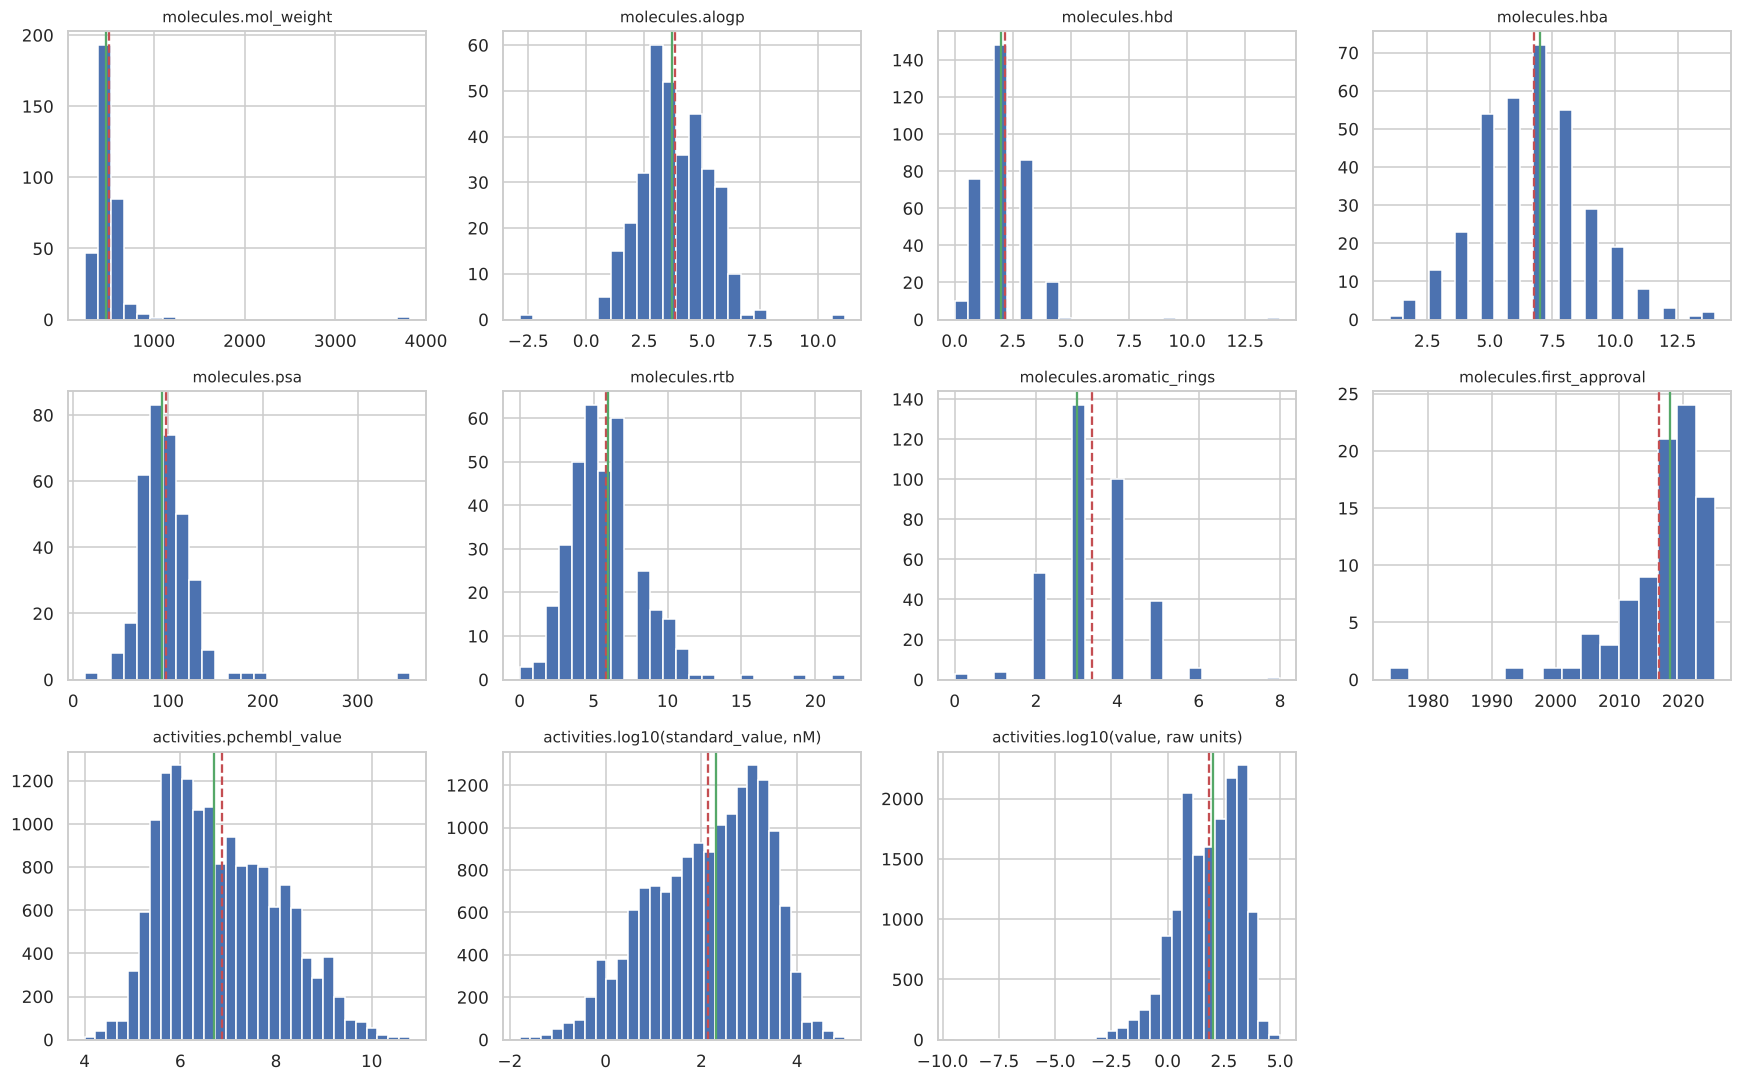

In [3]:
def hist(ax, s, title, bins=25):
    s = s.dropna()
    ax.hist(s, bins=bins, color="#4C72B0", edgecolor="white")
    ax.axvline(s.mean(), color="#C44E52", ls="--", lw=1.5); ax.axvline(s.median(), color="#55A868", lw=1.5)
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel()[:7], D):
    hist(ax, mol[c], f"molecules.{c}")
hist(axes.ravel()[7], mol.first_approval, "molecules.first_approval", bins=range(1974, 2028, 3))
hist(axes[2, 0], act.pchembl_value, "activities.pchembl_value", bins=30)
hist(axes[2, 1], np.log10(act.standard_value), "activities.log10(standard_value, nM)", bins=30)
hist(axes[2, 2], np.log10(act.value), "activities.log10(value, raw units)", bins=30)
axes[2, 3].axis("off")
plt.tight_layout(); plt.show()

**Conclusion 6.2**
- `alogp`, `aromatic_rings` and `hba` look like bell-shaped single-peaked distributions; `hbd`, `psa` and `rtb` have a clear right tail; `mol_weight` has a main body around 400–540 plus a long, thin tail of heavy entries.
- `first_approval` piles up in the last decade (a young drug class).
- `pchembl_value` is roughly bell-shaped with a slightly longer right tail (the very potent compounds). On the log scale the concentration `standard_value` becomes a regular, single-peaked distribution spanning about six orders of magnitude: a linear scale hides almost all of it.
- The raw `value` (last panel) is plotted on a log scale only to show its spread; it mixes nM, µM and p-values, so it is not a meaningful distribution and will not be used.

### 6.3 Categorical variables: frequencies
Categorical variables here include ordinal codes (`max_phase`, `ro5_violations`, `max_phase_for_ind`). For each column we count the distinct values, the most frequent value and how many values appear only once (a sign of very long tails).

In [4]:
cat_cols = {"molecules": ["molecule_type", "max_phase", "ro5_violations"],
            "activities": ["standard_type", "standard_units", "type", "units", "target_pref_name"],
            "indications": ["efo_term", "mesh_heading", "max_phase_for_ind"],
            "mechanisms": ["action_type", "mechanism_of_action", "max_phase"],
            "targets": ["organism", "target_type"]}
rows = []
for ds, cols in cat_cols.items():
    for c in cols:
        s = files[ds][c]; vc = s.value_counts()
        rows.append({"dataset": ds, "column": c, "n_unique": len(vc), "most frequent": str(vc.index[0])[:45],
                     "frequency": int(vc.iloc[0]), "% of rows": round(100 * vc.iloc[0] / len(s), 1),
                     "values seen once": int((vc == 1).sum()), "missing": int(s.isna().sum())})
pd.DataFrame(rows)

,dataset,column,n_unique,most frequent,frequency,% of rows,values seen once,missing
0,molecules,molecule_type,4,Small molecule,343,84.3,0,0
1,molecules,max_phase,4,2.0,156,38.3,0,0
2,molecules,ro5_violations,4,0.0,201,49.4,0,64
3,activities,standard_type,3,Kd,9093,58.1,0,0
4,activities,standard_units,1,nM,15655,100.0,0,0
5,activities,type,11,Kd,6679,42.7,0,0
6,activities,units,15,nM,13678,87.4,5,675
7,activities,target_pref_name,381,Receptor-type tyrosine-protein kinase FLT3,726,4.6,17,0
8,indications,efo_term,495,neoplasm,178,6.2,207,0
9,indications,mesh_heading,362,Neoplasms,283,9.9,140,0


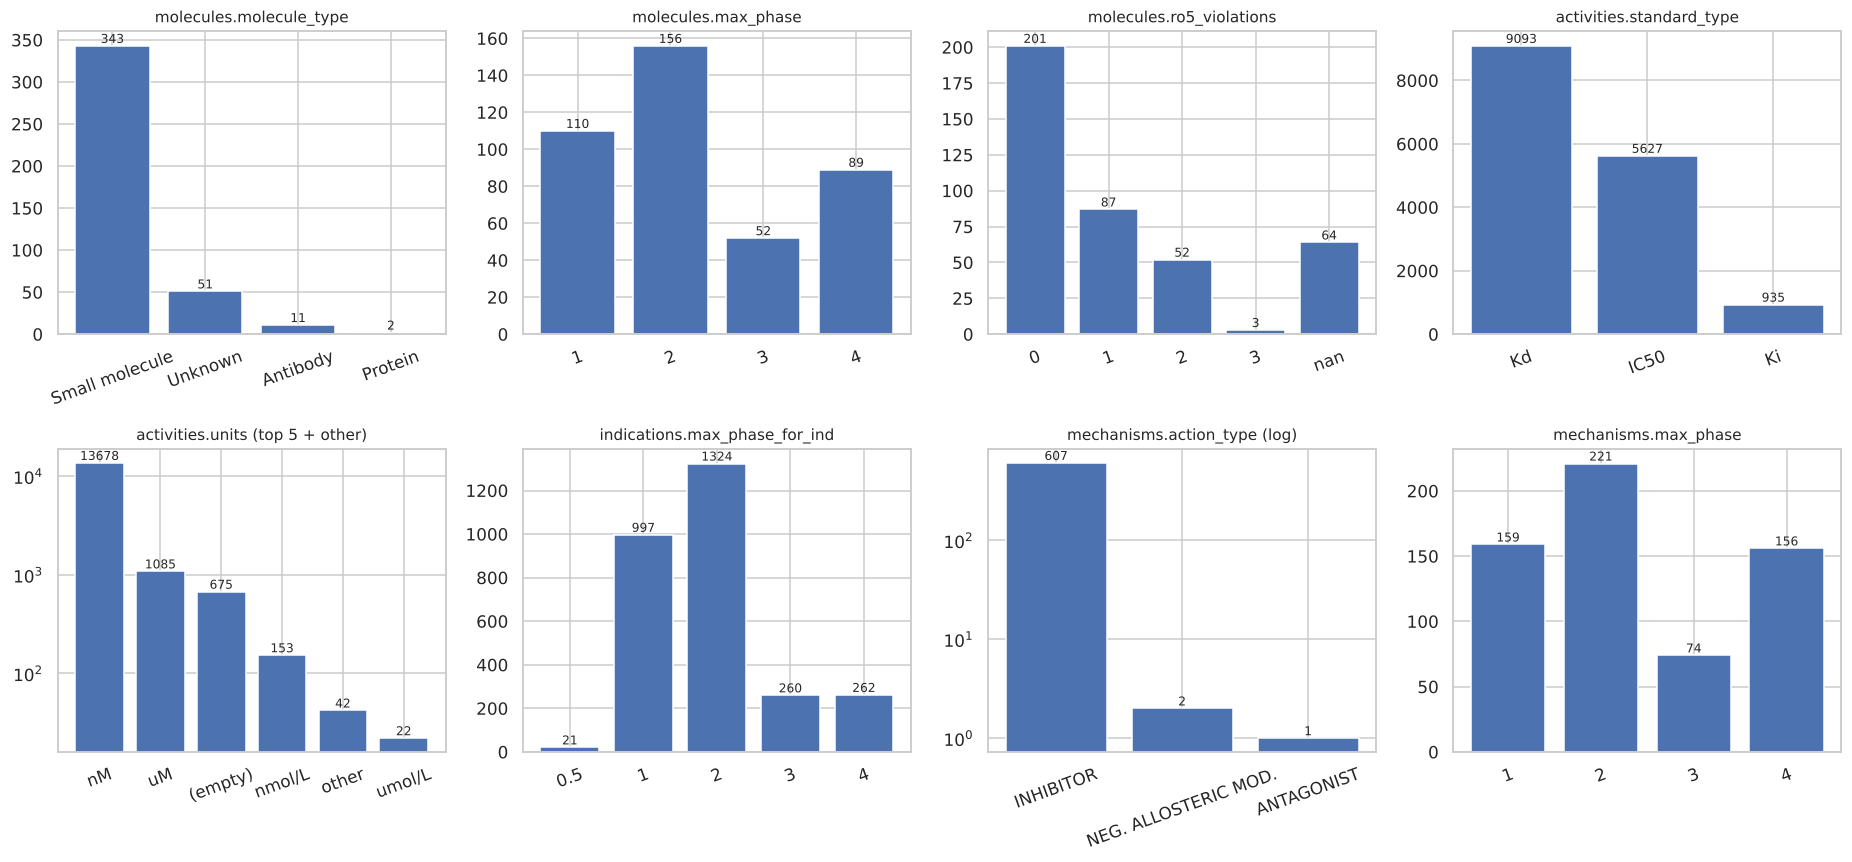

In [5]:
def bars(ax, s, title, log=False, order=None):
    vc = s.value_counts(dropna=False)
    vc = vc.reindex(order) if order is not None else vc.sort_index() if s.dtype.kind in "fi" else vc
    vc.index = [str(i) if not (isinstance(i, float) and i.is_integer()) else str(int(i)) for i in vc.index]
    ax.bar(vc.index, vc.values, color="#4C72B0")
    for x, v in zip(range(len(vc)), vc.values):
        ax.text(x, v, f"{v}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", rotation=20)
    if log: ax.set_yscale("log")

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
bars(axes[0, 0], mol.molecule_type, "molecules.molecule_type")
bars(axes[0, 1], mol.max_phase, "molecules.max_phase")
bars(axes[0, 2], mol.ro5_violations, "molecules.ro5_violations")
bars(axes[0, 3], act.standard_type, "activities.standard_type")
u = act.units.fillna("(empty)"); top_units = u.value_counts().head(5).index
bars(axes[1, 0], u.where(u.isin(top_units), "other"), "activities.units (top 5 + other)", log=True)
bars(axes[1, 1], ind.max_phase_for_ind, "indications.max_phase_for_ind")
bars(axes[1, 2], mech.action_type.str.replace("NEGATIVE ALLOSTERIC MODULATOR", "NEG. ALLOSTERIC MOD."), "mechanisms.action_type (log)", log=True)
bars(axes[1, 3], mech.max_phase, "mechanisms.max_phase")
plt.tight_layout(); plt.show()

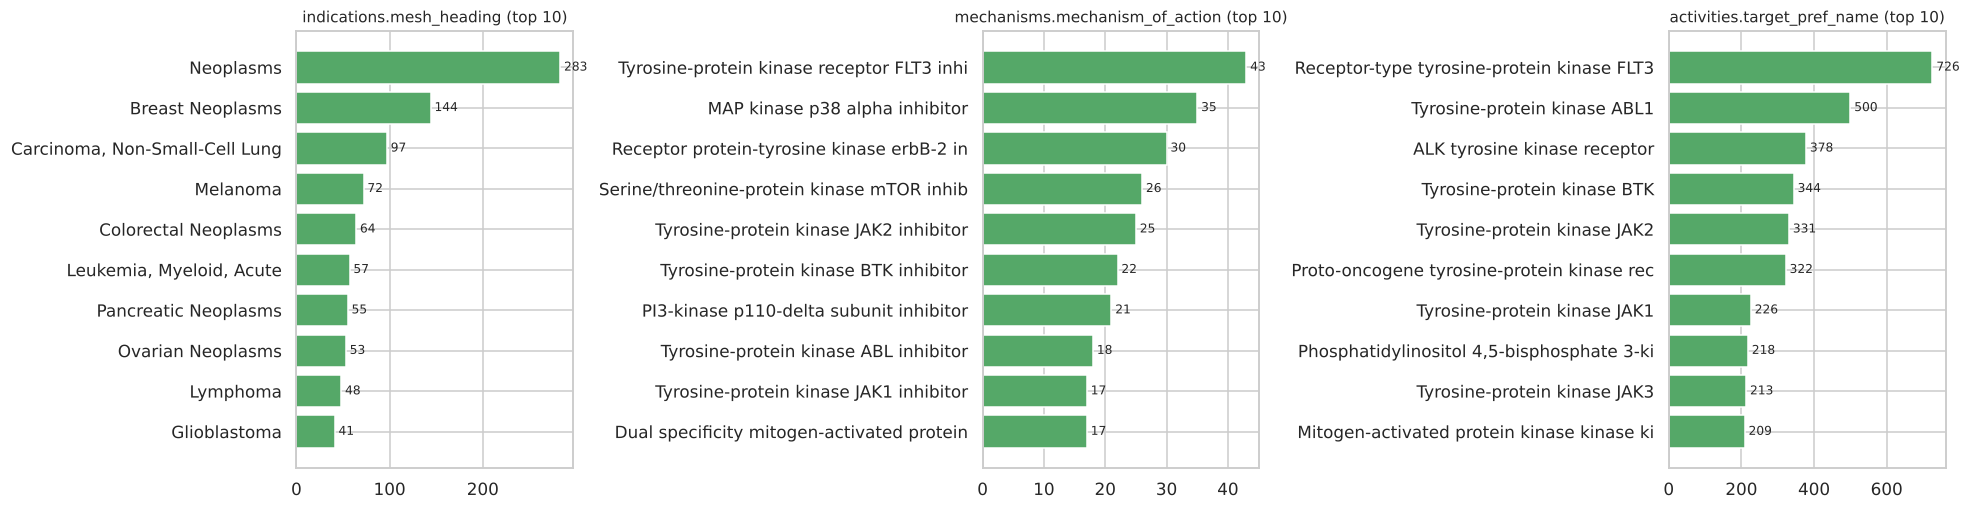

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (s, t) in zip(axes, [(ind.mesh_heading, "indications.mesh_heading (top 10)"),
                              (mech.mechanism_of_action, "mechanisms.mechanism_of_action (top 10)"),
                              (act.target_pref_name, "activities.target_pref_name (top 10)")]):
    vc = s.value_counts().head(10)[::-1]
    ax.barh([x[:42] for x in vc.index], vc.values, color="#55A868"); ax.set_title(t, fontsize=10)
    for y, v in enumerate(vc.values): ax.text(v, y, f" {v}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Conclusion 6.3**
- **`molecule_type`:** 343 small molecules (84%), 51 *Unknown* (13%), 11 antibodies and 2 proteins.
- **`max_phase`:** 110 molecules in phase 1 (27%), 156 in phase 2 (38%), 52 in phase 3 (13%) and 89 approved (22%). These counts are on the raw rows, so salt forms are counted twice (Phase 2 showed 67 unique approved small molecules).
- **`ro5_violations`:** 201 molecules break no rule, 87 one, 52 two and 3 three (343 with a value).
- **`standard_type`:** Kd 9 093 (58%), IC50 5 627 (36%), Ki 935 (6%): the potency table is dominated by Kd. **`units`:** nM 13 678 (87%), uM 1 085 (7%), empty 675 (4%), the rest are rare spellings.
- **`max_phase_for_ind`:** 997 records in phase 1, 1 324 in phase 2, 260 in phase 3, 262 approved and 21 at 0.5: most indication records are investigational.
- **`action_type`:** 607 INHIBITOR against 2 NEGATIVE ALLOSTERIC MODULATOR and 1 ANTAGONIST (an almost constant variable, log scale).
- **High-cardinality text categories have long tails:** `efo_term` has 495 values, 207 of them appearing only once (42%); `mesh_heading` 362 values, 140 once (39%); `mechanism_of_action` 102 values, 43 once. The most frequent values are generic (*Neoplasms* 283 rows = 9.9%; *FLT3 inhibitor* 43 = 7.0%). Disease and mechanism labels will need grouping to be useful.
- **Kinases measured:** FLT3 (726 records), ABL1 (500), ALK (378), BTK (344) and JAK2 (331) lead; 17 of the 381 kinases appear only once.
- `targets.organism` and `targets.target_type` have a single value (constant).

### 6.4 Identifiers: uniqueness and frequency
For an identifier we ask: is it unique (a primary key) or does it repeat (a foreign key), and if it repeats, how unevenly?

In [7]:
specs = [("molecules", "molecule_chembl_id"), ("targets", "target_chembl_id"), ("molecules", "inchi_key"), ("molecules", "name"),
         ("activities", "molecule_chembl_id"), ("activities", "target_chembl_id"), ("activities", "assay_chembl_id"),
         ("indications", "molecule_chembl_id"), ("mechanisms", "molecule_chembl_id"), ("mechanisms", "target_chembl_id")]
rows = []
for ds, c in specs:
    vc = files[ds][c].value_counts()
    rows.append({"dataset": ds, "column": c, "rows with a value": int(vc.sum()), "unique": len(vc),
                 "% unique": round(100 * len(vc) / vc.sum(), 1), "max frequency": int(vc.max()),
                 "median frequency": float(vc.median()), "mean frequency": round(vc.mean(), 1)})
pd.DataFrame(rows)

,dataset,column,rows with a value,unique,% unique,max frequency,median frequency,mean frequency
0,molecules,molecule_chembl_id,407,407,100.0,1,1.0,1.0
1,targets,target_chembl_id,548,548,100.0,1,1.0,1.0
2,molecules,inchi_key,345,345,100.0,1,1.0,1.0
3,molecules,name,407,407,100.0,1,1.0,1.0
4,activities,molecule_chembl_id,15655,262,1.7,918,21.0,59.8
5,activities,target_chembl_id,15655,381,2.4,726,22.0,41.1
6,activities,assay_chembl_id,15655,6679,42.7,47,1.0,2.3
7,indications,molecule_chembl_id,2864,359,12.5,88,4.0,8.0
8,mechanisms,molecule_chembl_id,610,407,66.7,7,1.0,1.5
9,mechanisms,target_chembl_id,610,99,16.2,43,2.0,6.2


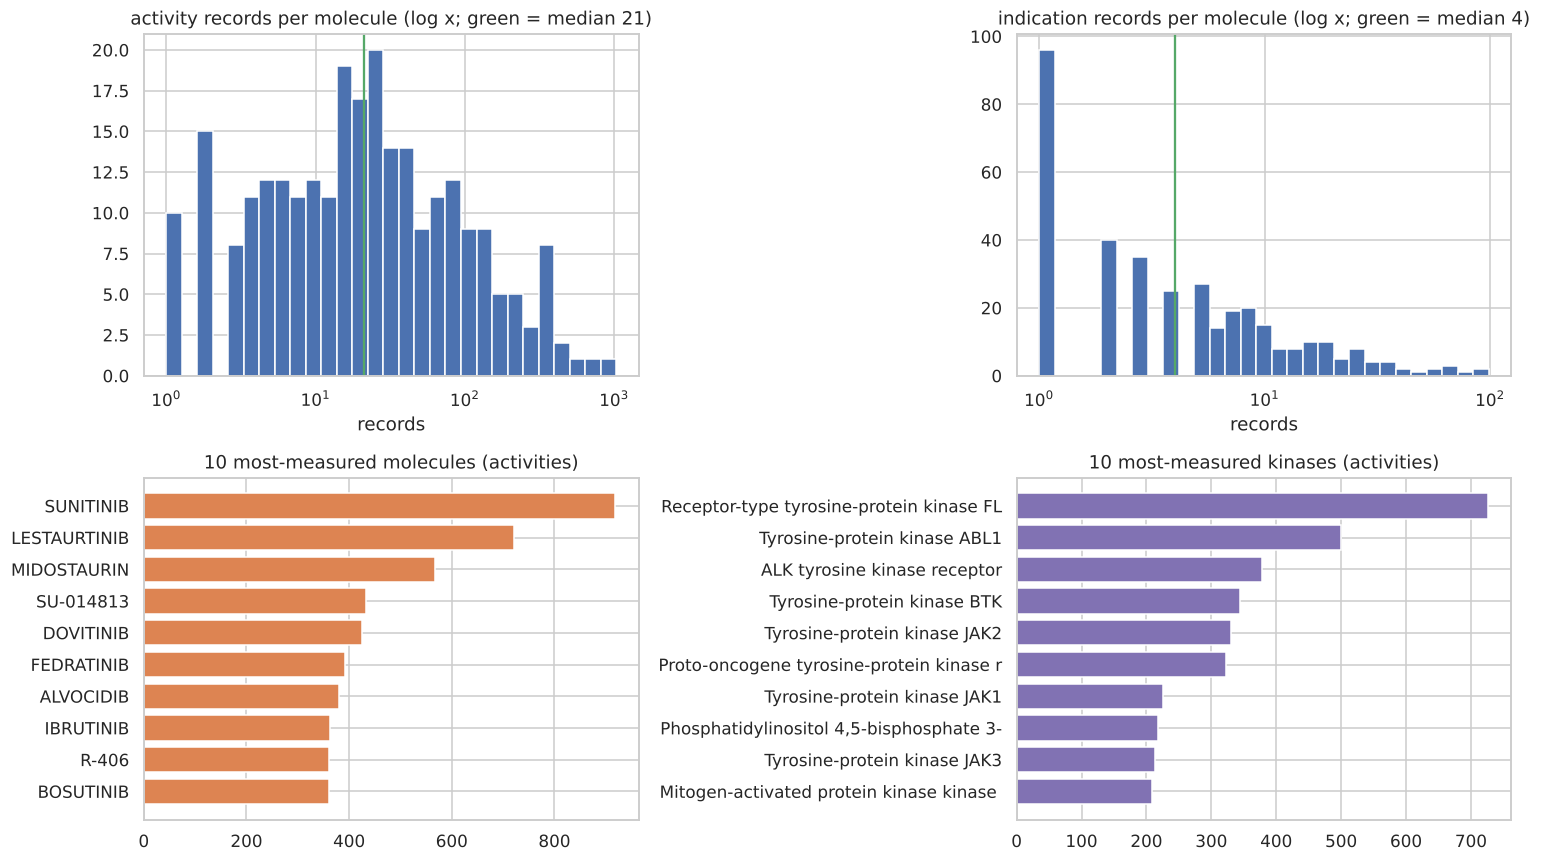

In [8]:
nm = mol.set_index("molecule_chembl_id").name
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (s, t) in zip(axes[0], [(act.molecule_chembl_id, "activity records per molecule"), (ind.molecule_chembl_id, "indication records per molecule")]):
    c = s.value_counts()
    ax.hist(c, bins=np.logspace(0, np.log10(c.max()) + 0.05, 30), color="#4C72B0", edgecolor="white"); ax.set_xscale("log")
    ax.axvline(c.median(), color="#55A868"); ax.set_title(f"{t} (log x; green = median {c.median():.0f})"); ax.set_xlabel("records")
vc = act.molecule_chembl_id.value_counts().head(10)[::-1]
axes[1, 0].barh([nm[i] for i in vc.index], vc.values, color="#DD8452"); axes[1, 0].set_title("10 most-measured molecules (activities)")
vc = act.target_pref_name.value_counts().head(10)[::-1]
axes[1, 1].barh([x[:40] for x in vc.index], vc.values, color="#8172B3"); axes[1, 1].set_title("10 most-measured kinases (activities)")
plt.tight_layout(); plt.show()

**Conclusion 6.4**
- **Primary keys are unique:** `molecule_chembl_id` (407 of 407), `target_chembl_id` (548 of 548), `inchi_key` (345 of 345 present) and `name` (407 of 407) have no repeated value.
- **Foreign keys repeat, very unevenly.** In `activities` a molecule has a median of 21 records but a mean of 60 and a maximum of 918 (sunitinib), followed by lestaurtinib (722) and midostaurin (567). A kinase has a median of 22 records and a maximum of 726 (FLT3). The assays are mostly small: 6 679 distinct assays, 71% of them (4 750) contribute a single row, the largest contributes 47.
- **`indications`:** a molecule has a median of 4 records and a mean of 8, with a maximum of 88. **`mechanisms`:** a molecule has a median of 1 mechanism record (maximum 7) and a kinase a median of 2 (maximum 43, mean 6.2).
- The distributions are heavy-tailed (the median is far below the mean): a few well-studied molecules and kinases carry most of the records, so any statistic over *records* describes them more than the typical molecule.

### 6.5 Text and structure columns: length, missingness, validity
For text columns: how many are missing and how long are the values (a sudden very long value is a hint of something unusual). For the structure column `smiles` we also test **validity** with RDKit and count heavy atoms (non-hydrogen atoms, a measure of molecular size).

,dataset,column,missing,% missing,min length,median length,max length,distinct lengths
0,molecules,smiles,62,15.2,32,60.0,617,68
1,molecules,inchi_key,62,15.2,27,27.0,27,1
2,molecules,name,0,0.0,5,10.0,39,24
3,mechanisms,mechanism_of_action,0,0.0,25,39.0,71,32
4,activities,target_pref_name,0,0.0,14,36.0,78,51
5,targets,pref_name,0,0.0,10,36.0,78,58
6,indications,efo_term,0,0.0,4,18.0,59,45
7,indications,mesh_heading,0,0.0,4,19.0,48,42


SMILES present: 345 | valid for RDKit: 345 | invalid: 0
heavy atoms: min 17 | median 33 | 75th pct 38 | max 270
InChIKey length values: [27]
longest names: [39, 35, 29] -> MOMELOTINIB DIHYDROCHLORIDE MONOHYDRATE


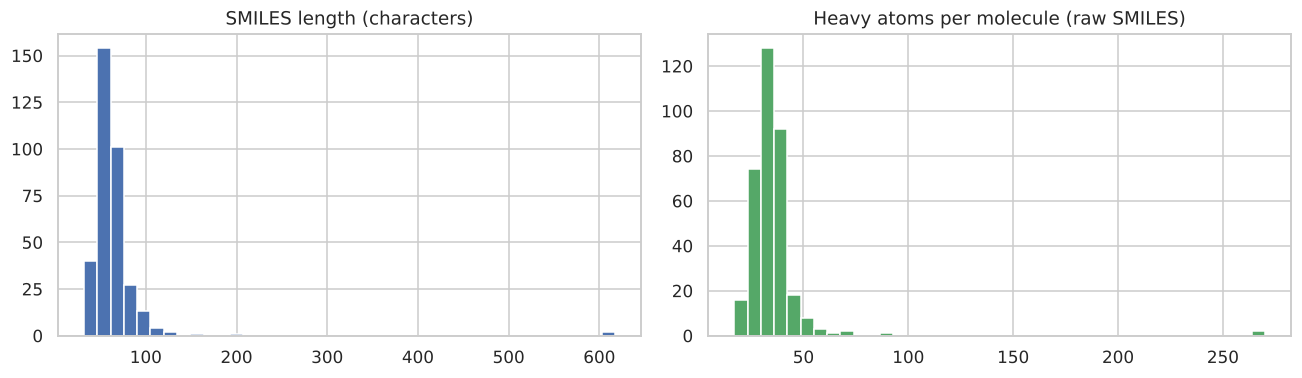

In [9]:
text_cols = [("molecules", "smiles"), ("molecules", "inchi_key"), ("molecules", "name"), ("mechanisms", "mechanism_of_action"),
             ("activities", "target_pref_name"), ("targets", "pref_name"), ("indications", "efo_term"), ("indications", "mesh_heading")]
rows = []
for ds, c in text_cols:
    s = files[ds][c]; L = s.dropna().str.len()
    rows.append({"dataset": ds, "column": c, "missing": int(s.isna().sum()), "% missing": round(100 * s.isna().mean(), 1),
                 "min length": int(L.min()), "median length": float(L.median()), "max length": int(L.max()), "distinct lengths": L.nunique()})
display(pd.DataFrame(rows))

smi = mol.smiles.dropna()
mols = smi.apply(Chem.MolFromSmiles)
valid = mols.notna()
heavy = mols[valid].apply(lambda m: m.GetNumHeavyAtoms())
print("SMILES present:", len(smi), "| valid for RDKit:", int(valid.sum()), "| invalid:", int((~valid).sum()))
print("heavy atoms: min %d | median %d | 75th pct %d | max %d" % (heavy.min(), heavy.median(), heavy.quantile(.75), heavy.max()))
print("InChIKey length values:", mol.inchi_key.dropna().str.len().unique().tolist())
print("longest names:", mol.name.str.len().nlargest(3).tolist(), "->", mol.loc[mol.name.str.len().idxmax(), "name"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(smi.str.len(), bins=40, color="#4C72B0", edgecolor="white"); axes[0].set_title("SMILES length (characters)")
axes[1].hist(heavy, bins=40, color="#55A868", edgecolor="white"); axes[1].set_title("Heavy atoms per molecule (raw SMILES)")
plt.tight_layout(); plt.show()

**Conclusion 6.5**
- **Missingness:** all text columns are complete except `smiles` and `inchi_key` (62 missing each, the molecules without structure).
- **SMILES validity:** all 345 SMILES are valid for RDKit. Length goes from 32 to 617 characters (median 60); the two 617-character entries are the brimapitide peptides. The next longest are ridaforolimus (199) and salt forms such as gilteritinib fumarate (149), where the counter-ion adds characters.
- **Molecular size:** a typical molecule has 33 heavy atoms (75% have 38 or fewer), minimum 17, and the maximum of 270 are the two peptides. These counts come from the raw SMILES, so salt forms include their counter-ions.
- **InChIKey:** every key has exactly 27 characters (the standard format).
- **Labels:** drug names are 5 to 39 characters; the longest, *MOMELOTINIB DIHYDROCHLORIDE MONOHYDRATE*, shows that salt and hydrate names appear in the `name` column. `mechanism_of_action`, `efo_term` and `mesh_heading` are short free-text labels (median 39, 18 and 19 characters).

**Output of Step 6.** `univariate_numerical_statistics.csv` plus the distribution plots above. The main lessons: molecular weight, polarity counts and all concentration values are skewed; the categorical labels have long tails; and the records of `activities`, `indications` and `mechanisms` are concentrated on a few molecules and kinases.

---
# Step 7 — Bivariate analysis
Objective: study the relationships between pairs of variables, with the tool that fits the types: **correlation and scatter plots** for numerical pairs, **group comparisons** for a numerical variable against a categorical one, and **contingency tables** for two categorical variables.

### 7.1 Correlation between numerical variables
Which columns are suitable? The seven ChEMBL descriptors (Pearson, for roughly linear relations), and, with the ordinal `max_phase` and the year `first_approval`, **Spearman** (rank-based, valid for ordinal codes and skewed variables). Not suitable: identifiers, constant columns, and pairs where one variable is a mathematical transformation of the other (checked in the second cell). We also compare with the correlations after recomputing the descriptors on the parent structures.

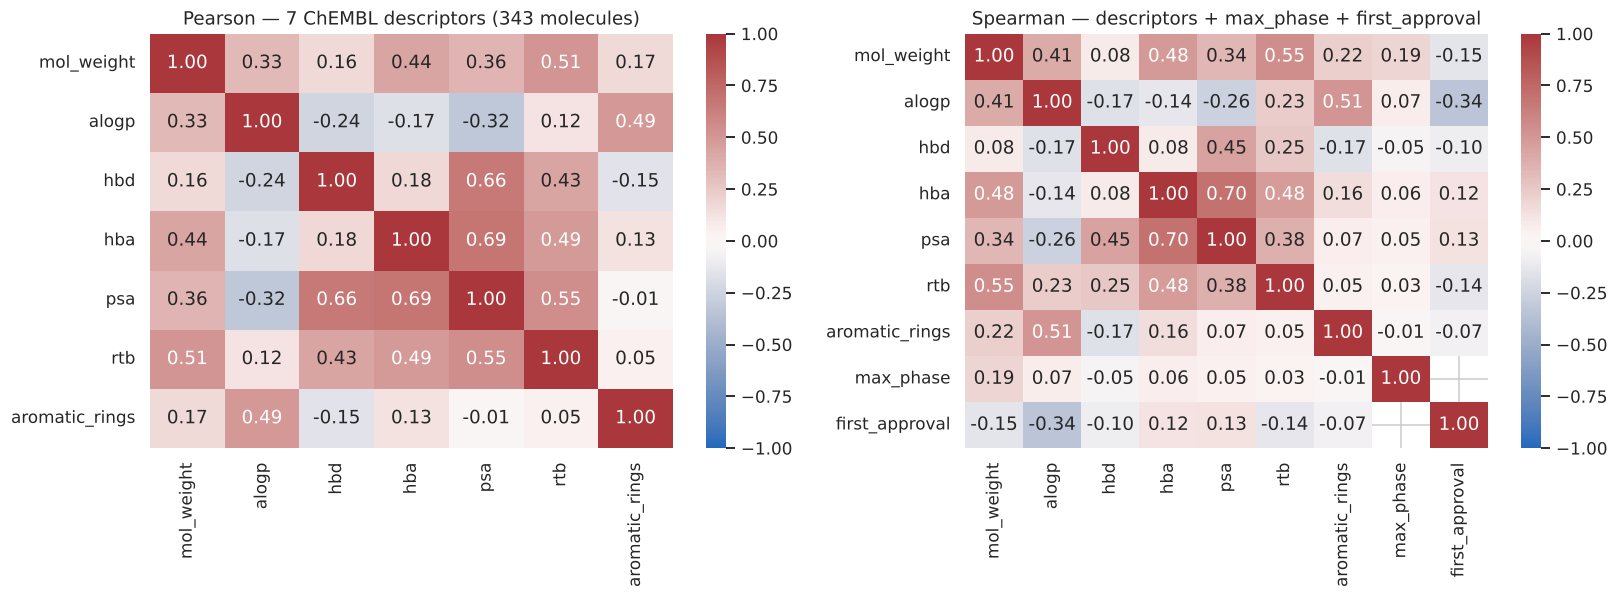

strongest Pearson pairs:
hba         psa               0.69
hbd         psa               0.66
psa         rtb               0.55
mol_weight  rtb               0.51
alogp       aromatic_rings    0.49
hba         rtb               0.49
pairs with |r| >= 0.70: 0
Spearman with first_approval (n = 88): {'mol_weight': -0.15, 'alogp': -0.34, 'hbd': -0.1, 'hba': 0.12, 'psa': 0.13, 'rtb': -0.14, 'aromatic_rings': -0.07}
Spearman with max_phase: {'mol_weight': 0.19, 'alogp': 0.07, 'hbd': -0.05, 'hba': 0.06, 'psa': 0.05, 'rtb': 0.03, 'aromatic_rings': -0.01}


In [10]:
pear = mol[D].corr()
spear = mol[D + ["max_phase", "first_approval"]].corr(method="spearman")
pear.round(3).to_csv(REPORT_DIR / "correlation_matrix_molecules.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
sns.heatmap(pear, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson — 7 ChEMBL descriptors (343 molecules)")
sns.heatmap(spear, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Spearman — descriptors + max_phase + first_approval")
plt.tight_layout(); plt.show()

tri = pear.where(np.triu(np.ones(pear.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
print("strongest Pearson pairs:"); print(tri.head(6).round(2).to_string())
print("pairs with |r| >= 0.70:", int((tri.abs() >= 0.70).sum()))
print("Spearman with first_approval (n = %d):" % mol.first_approval.notna().sum(), spear["first_approval"].drop(["first_approval", "max_phase"]).round(2).to_dict())
print("Spearman with max_phase:", spear["max_phase"].drop(["max_phase", "first_approval"]).round(2).to_dict())

In [11]:
# the same descriptors recomputed on the parent structures (322 unique molecules), in memory
kp = k[DESC].corr(); kp.index = kp.columns = D
delta = (kp - pear).where(np.triu(np.ones(pear.shape, dtype=bool), 1)).stack()
print("largest changes in Pearson r after recomputing on the parent structures:")
print(pd.DataFrame({"ChEMBL (raw)": pear.where(np.triu(np.ones(pear.shape, dtype=bool), 1)).stack()[delta.abs().nlargest(5).index].round(2),
                    "recomputed": kp.where(np.triu(np.ones(pear.shape, dtype=bool), 1)).stack()[delta.abs().nlargest(5).index].round(2)}))
print("largest absolute change:", round(float(delta.abs().max()), 3))

# H-bond acceptors: ChEMBL's count vs RDKit's, for the molecules without counter-ion
ns = small[~small.salt].dropna(subset=["hba"])
rd_hba = ns.smiles.apply(lambda s: rdMolDescriptors.CalcNumHBA(Chem.MolFromSmiles(s)))
print("\nhba: ChEMBL differs from RDKit's count for", int((rd_hba != ns.hba).sum()), "of", len(ns), "molecules without counter-ion",
      "| mean ChEMBL %.2f vs RDKit %.2f | ChEMBL higher in %d, lower in %d" % (ns.hba.mean(), rd_hba.mean(), int((ns.hba > rd_hba).sum()), int((ns.hba < rd_hba).sum())))

# unsuitable pairs in activities
a = act.assign(log10_standard_value=np.log10(act.standard_value))
print("\nactivities: pchembl_value vs log10(standard_value): Pearson %.3f" % a.pchembl_value.corr(a.log10_standard_value))
print("            pchembl_value vs standard_value (linear): Pearson %.2f | Spearman %.2f" % (a.pchembl_value.corr(a.standard_value), a.pchembl_value.corr(a.standard_value, method="spearman")))
print("            raw value vs standard_value: Pearson %.2f | Spearman %.2f" % (a.value.corr(a.standard_value), a.value.corr(a.standard_value, method="spearman")))

largest changes in Pearson r after recomputing on the parent structures:
                           ChEMBL (raw)  recomputed
mol_weight psa                     0.36        0.51
           hba                     0.44        0.58
hba        aromatic_rings          0.13       -0.01
mol_weight rtb                     0.51        0.63
           aromatic_rings          0.17        0.26
largest absolute change: 0.155

hba: ChEMBL differs from RDKit's count for 117 of 294 molecules without counter-ion | mean ChEMBL 6.77 vs RDKit 6.26 | ChEMBL higher in 117, lower in 0

activities: pchembl_value vs log10(standard_value): Pearson -1.000
            pchembl_value vs standard_value (linear): Pearson -0.46 | Spearman -1.00
            raw value vs standard_value: Pearson 0.83 | Spearman 0.82


**Conclusion 7.1**
- **Descriptors:** the strongest correlations are `hba`–`psa` (0.69), `hbd`–`psa` (0.66), `psa`–`rtb` (0.55), `mol_weight`–`rtb` (0.51), `alogp`–`aromatic_rings` (0.49) and `hba`–`rtb` (0.49). Polar surface area, acceptors, donors and flexibility rise together; lipophilicity rises with the number of aromatic rings and falls with polarity (`alogp`–`psa` −0.32). **No pair reaches 0.70**: the descriptors are related but not redundant.
- **Effect of the salts:** after recomputing on the parent structures the correlations of molecular weight become stronger (`mol_weight`–`psa` 0.36 → 0.51, –`hba` 0.44 → 0.58, –`rtb` 0.51 → 0.63; largest change 0.155). The counter-ions in ChEMBL's molecular weight add noise that weakens its relation with the other descriptors. (The change for `hba` – `aromatic_rings`, 0.13 → −0.01, has another cause: ChEMBL and RDKit do not count H-bond acceptors in the same way; ChEMBL's count is higher for 117 of the 294 molecules without counter-ion and never lower, mean 6.77 against 6.26. We did not investigate the counting rules, so the recomputed `hba` is a slightly different variable.)
- **`max_phase`:** no descriptor is related to the development phase (all |ρ| ≤ 0.19, the largest being molecular weight, which is partly a salt effect, see 7.3).
- **`first_approval`** (88 molecules): moderate relation with lipophilicity (ρ = −0.34): the more recently approved drugs tend to be less lipophilic; weak for the others (|ρ| ≤ 0.15). With 88 points this is descriptive only.
- **Unsuitable pairs:** `pchembl_value` and log₁₀(`standard_value`) are perfectly (negatively) correlated (r = −1.000): one is a transformation of the other, so they are the same information, and only one should be kept. A linear correlation of `pchembl_value` with the raw concentration is misleading (Pearson −0.46 against Spearman −1.00) because of the skewness of the concentration. The 0.83 correlation between `value` and `standard_value` is meaningless because `value` mixes units.
- The Pearson matrix is saved as `correlation_matrix_molecules.csv`.

### 7.2 Scatter plots
Scatter plots show what a correlation coefficient hides. (a) A pair plot of five descriptors for the 343 small molecules, colored by approved / exploratory. (b) Three specific relations: molecular weight against polar surface area for salt forms vs other molecules; `pchembl_value` against the concentration; and the raw `value` against `standard_value` colored by raw unit.

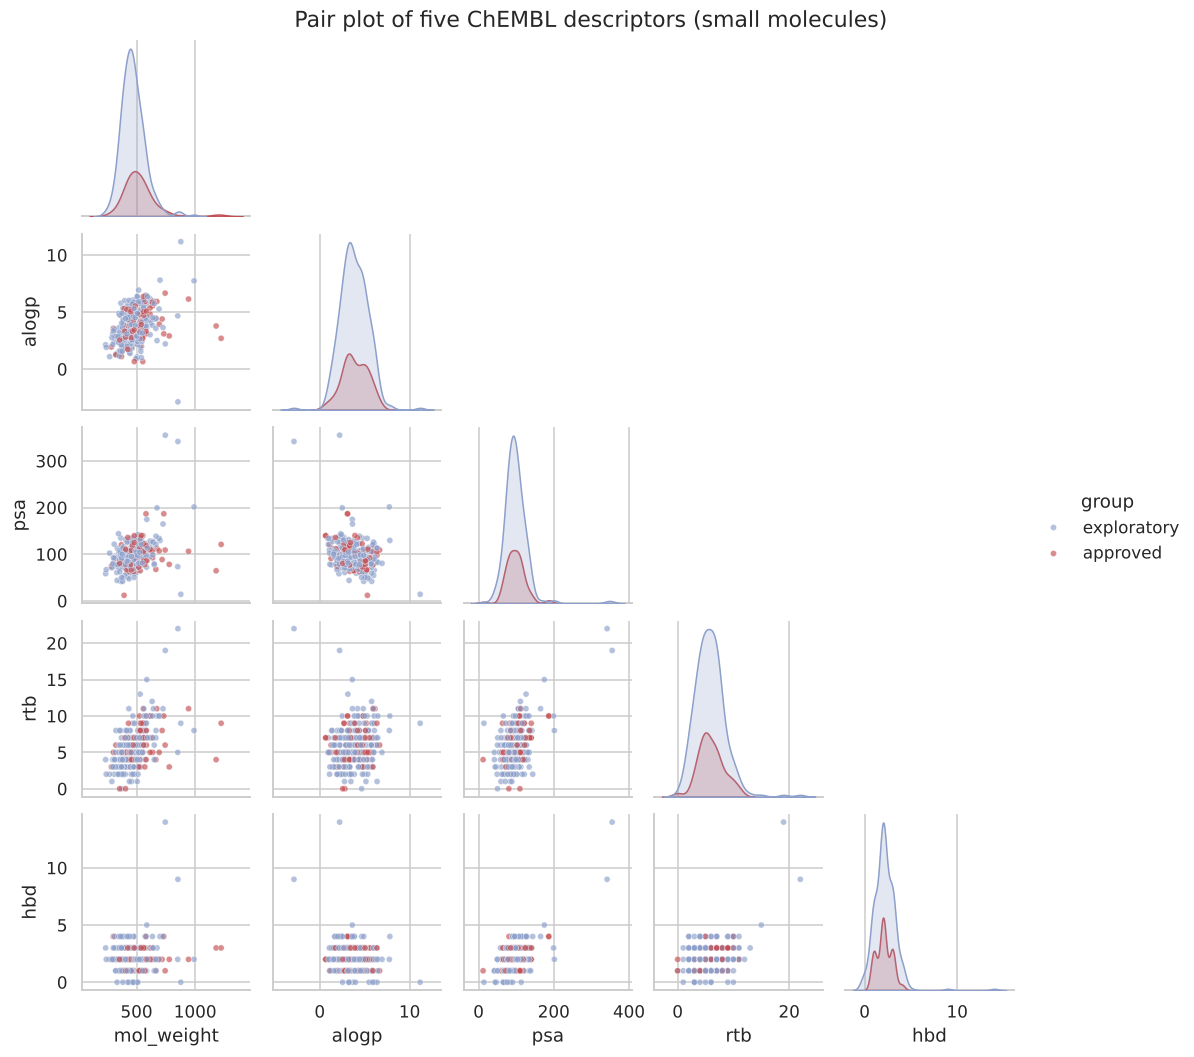

In [12]:
pp = small.dropna(subset=["alogp"]).assign(group=lambda d: d.approved.map({True: "approved", False: "exploratory"}))
g = sns.pairplot(pp[["mol_weight", "alogp", "psa", "rtb", "hbd", "group"]], hue="group", corner=True, height=1.9,
                 palette={"approved": "#C44E52", "exploratory": "#8DA0CB"}, plot_kws={"s": 16, "alpha": .65})
g.fig.suptitle("Pair plot of five ChEMBL descriptors (small molecules)", y=1.01)
plt.show()

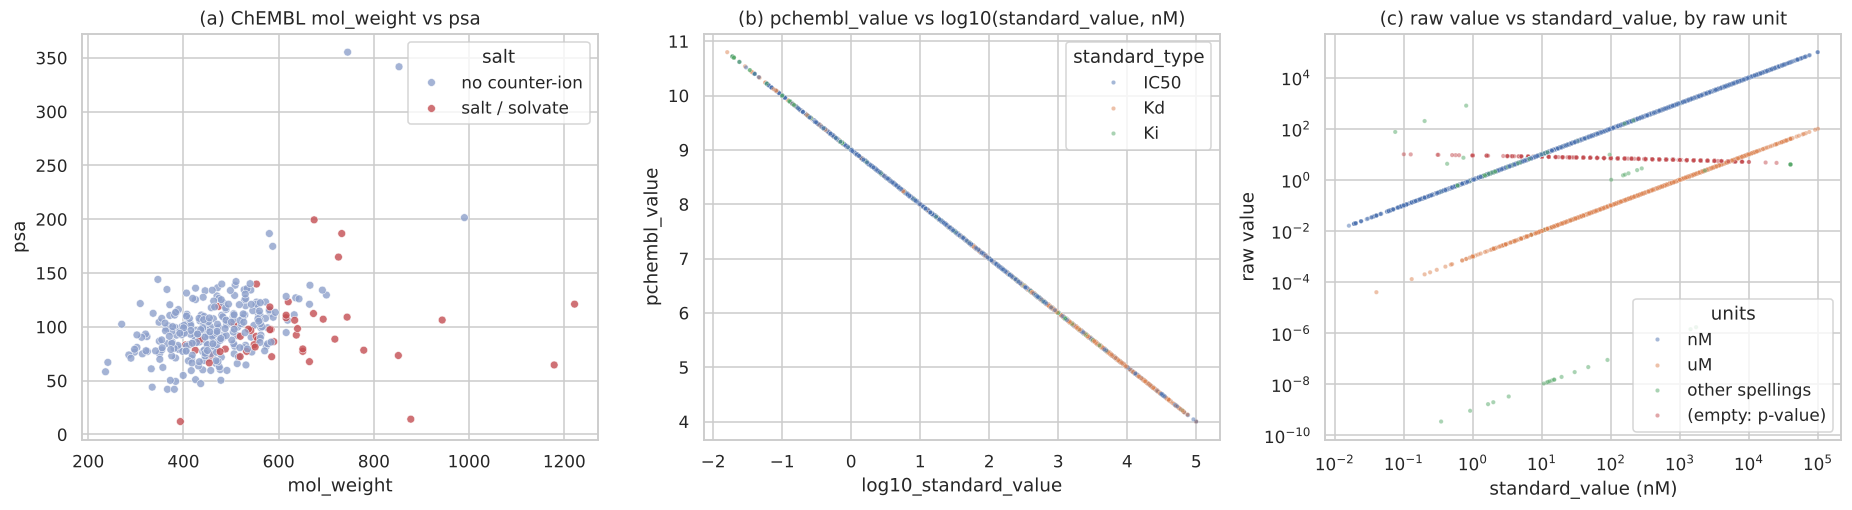

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.scatterplot(data=small.dropna(subset=["psa"]), x="mol_weight", y="psa", hue=small.salt.map({True: "salt / solvate", False: "no counter-ion"}),
                palette={"salt / solvate": "#C44E52", "no counter-ion": "#8DA0CB"}, s=26, alpha=.8, ax=axes[0])
axes[0].set_title("(a) ChEMBL mol_weight vs psa"); 

sns.scatterplot(data=a, x="log10_standard_value", y="pchembl_value", hue="standard_type", s=8, alpha=.5, ax=axes[1])
axes[1].set_title("(b) pchembl_value vs log10(standard_value, nM)")

ug = act.units.map(lambda u: "(empty: p-value)" if pd.isna(u) else (u if u in ("nM", "uM") else "other spellings"))
sns.scatterplot(x=act.standard_value, y=act.value, hue=ug, s=8, alpha=.5, ax=axes[2])
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlabel("standard_value (nM)"); axes[2].set_ylabel("raw value")
axes[2].set_title("(c) raw value vs standard_value, by raw unit")
plt.tight_layout(); plt.show()

**Conclusion 7.2**
- **(pair plot)** All the descriptor pairs form a single cloud: there are no separate groups of molecules, and **approved and exploratory molecules are mixed throughout** the cloud (the few approved points at very high molecular weight are salt forms, see (a) below). Positive slopes link polarity, size and flexibility (`psa`–`hbd`, `mol_weight`–`rtb`); `alogp` and `psa` are inversely related.
- **(a)** The salt forms (red) sit at higher molecular weight than the rest *without* a corresponding shift in polar surface area: the extra weight is the counter-ion, not a bigger drug. This is why the raw molecular weight is not comparable between a free base and its salt.
- **(b)** `pchembl_value` against log₁₀(concentration) is an exact straight line for the three measurement types: the two columns carry the same information.
- **(c)** The raw `value` against `standard_value` shows several parallel lines: each raw unit (nM, µM, other spellings) has a different conversion factor, and the p-value rows (empty unit) sit apart. This is why the raw `value` and `units` columns must not be used.

### 7.3 Numerical vs categorical variables
Three comparisons. (a) Do the descriptors differ across development phases? We use the Kruskal–Wallis test (no normality assumption), on the raw ChEMBL values and on the values recomputed on the parent structures. With 7 tests, a single p-value just under 0.05 is not convincing (a Bonferroni threshold would be 0.007). (b) Is the raw molecular weight different for salt forms? (c) Does potency depend on the measurement type?

,median phase 1/2/3/4 (ChEMBL),"Kruskal-Wallis p (ChEMBL, 343)","Kruskal-Wallis p (recomputed, 322)"
descriptor,,,
mol_weight,461.4 / 448.9 / 471.5 / 489.9,0.000,0.078
alogp,3.6 / 3.5 / 4.0 / 3.8,0.156,0.097
hbd,2.0 / 2.0 / 2.0 / 2.0,0.325,0.245
hba,6.0 / 7.0 / 7.0 / 7.0,0.581,0.865
psa,91.8 / 97.4 / 94.0 / 96.7,0.519,0.462
rtb,6.0 / 5.0 / 6.0 / 6.0,0.302,0.367
aromatic_rings,3.0 / 4.0 / 4.0 / 3.0,0.014,0.066


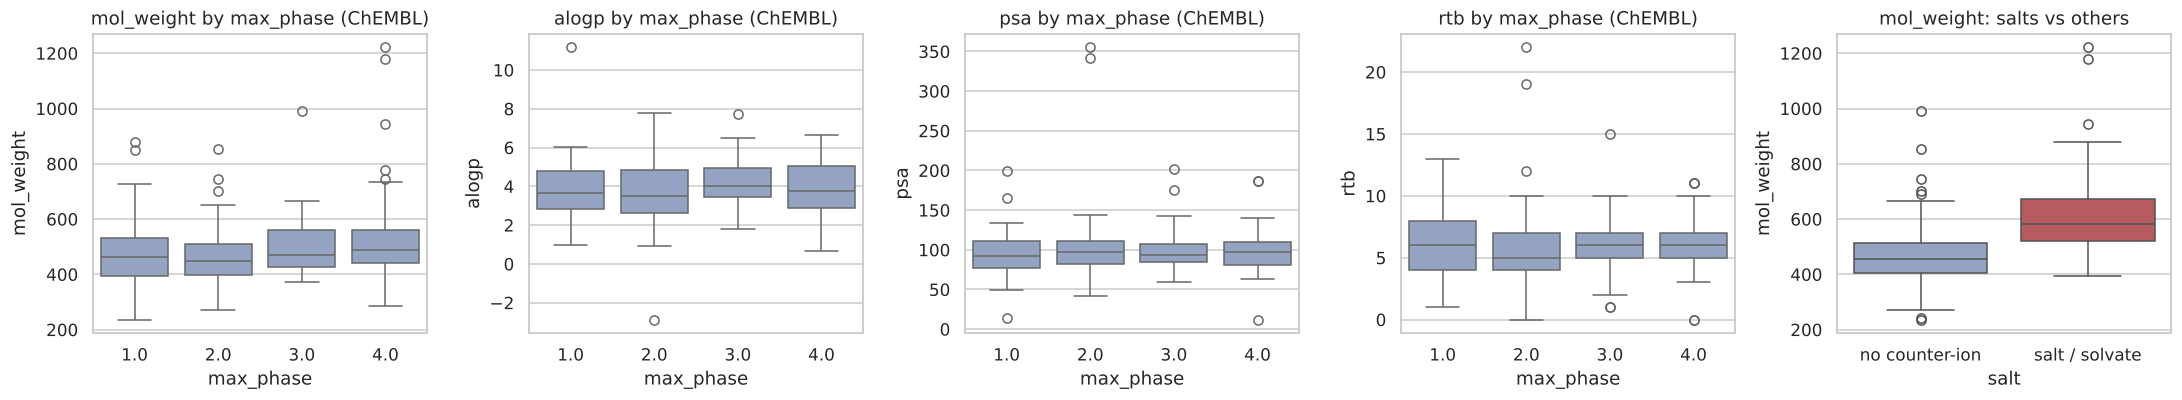

mol_weight median: salts 584 (n=49) vs others 455 (n=294) | Mann-Whitney p = 2.0e-13
share of salt forms among approved vs exploratory small molecules: 40% vs 6%


In [14]:
phases = [1, 2, 3, 4]
rows = []
for raw_c, par_c in zip(D, DESC):
    g_raw = [small.loc[small.max_phase == p, raw_c].dropna() for p in phases]
    g_par = [k.loc[k.max_phase == p, par_c] for p in phases]
    rows.append({"descriptor": raw_c, "median phase 1/2/3/4 (ChEMBL)": " / ".join(f"{x.median():.1f}" for x in g_raw),
                 "Kruskal-Wallis p (ChEMBL, 343)": kruskal(*g_raw)[1], "Kruskal-Wallis p (recomputed, 322)": kruskal(*g_par)[1]})
display(pd.DataFrame(rows).set_index("descriptor").round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, c in zip(axes[:4], ["mol_weight", "alogp", "psa", "rtb"]):
    sns.boxplot(data=small, x="max_phase", y=c, ax=ax, color="#8DA0CB"); ax.set_title(f"{c} by max_phase (ChEMBL)")
sns.boxplot(data=small, x="salt", y="mol_weight", ax=axes[4], palette=["#8DA0CB", "#C44E52"]); axes[4].set_xticklabels(["no counter-ion", "salt / solvate"]); axes[4].set_title("mol_weight: salts vs others")
plt.tight_layout(); plt.show()

s_, n_ = small[small.salt].mol_weight, small[~small.salt].mol_weight
print(f"mol_weight median: salts {s_.median():.0f} (n={len(s_)}) vs others {n_.median():.0f} (n={len(n_)}) | Mann-Whitney p = {mannwhitneyu(s_, n_).pvalue:.1e}")
print("share of salt forms among approved vs exploratory small molecules: %.0f%% vs %.0f%%" % (100 * small[small.approved].salt.mean(), 100 * small[~small.approved].salt.mean()))

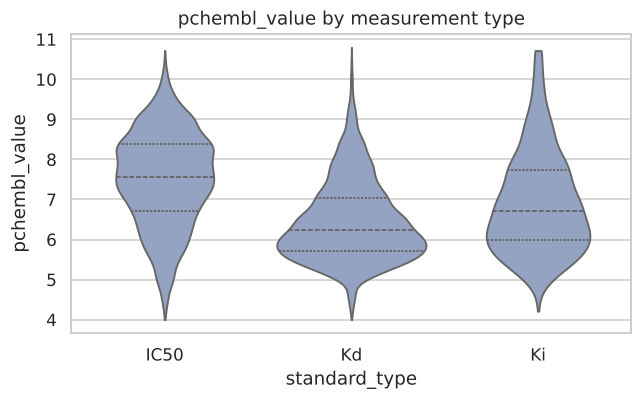

               count  median  mean   std
standard_type                           
IC50            5627    7.57  7.50  1.18
Kd              9093    6.25  6.46  1.00
Ki               935    6.70  6.93  1.27


Kruskal-Wallis p = 0.0


In [15]:
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.violinplot(data=act, x="standard_type", y="pchembl_value", inner="quartile", cut=0, ax=ax, color="#8DA0CB"); ax.set_title("pchembl_value by measurement type")
plt.tight_layout(); plt.show()
grp = act.groupby("standard_type").pchembl_value
print(grp.agg(["count", "median", "mean", "std"]).round(2))
print("Kruskal-Wallis p =", kruskal(*[g for _, g in grp]).pvalue)

**Conclusion 7.3**
- **(a) Descriptors vs phase.** On the raw ChEMBL values only the molecular weight differs across phases (medians 461 / 449 / 471 / 490, p < 0.001), and `aromatic_rings` is borderline (p = 0.014, not significant after correcting for 7 tests). **After recomputing on the parent structures none of the seven descriptors differs** (all p ≥ 0.066, molecular weight p = 0.078). The apparent molecular-weight effect comes from the salt forms: it vanishes once the counter-ion is removed.
- **(b) Salts.** Salt forms have a median molecular weight of 584 against 455 for the others (p ≈ 2×10⁻¹³). They are also much more frequent among approved drugs (40% of the approved small molecules are salt forms, against 6% of the exploratory ones), which is what creates the false phase effect above. Raw molecular weight should therefore not be compared across groups.
- **(c) Potency vs measurement type.** The three types are on different levels (median pChEMBL: IC50 7.57, Ki 6.70, Kd 6.25; p < 0.001). Kd values are systematically lower, so **pooling IC50, Ki and Kd would mix different scales**; potency must be compared within a type (or aggregated per type) as already recommended in Phase 2.

### 7.4 Relationships between categories
(a) Molecule type vs development phase; (b) oncology vs other diseases across the phase of the indication; (c) the amount of biological data per molecule across the development phase (a numerical count per molecule against a categorical phase). The strength of an association between two categorical variables is measured by Cramér's V (0 = none, 1 = perfect). The oncology flag is a keyword match on the MeSH heading (approximate).

molecule_type x max_phase: Cramer's V = 0.23


max_phase,1,2,3,4
molecule_type,,,,
Antibody,0,5,2,4
Protein,0,0,2,0
Small molecule,76,137,45,85
Unknown,34,14,3,0


oncology x indication phase: Cramer's V = 0.14


max_phase_for_ind,0.5,1.0,2.0,3.0,4.0
oncology,,,,,
oncology,17,852,1017,192,241
other disease,4,145,307,68,21


oncology share (%) by indication phase: {0.5: 81.0, 1.0: 85.5, 2.0: 76.8, 3.0: 73.8, 4.0: 92.0}


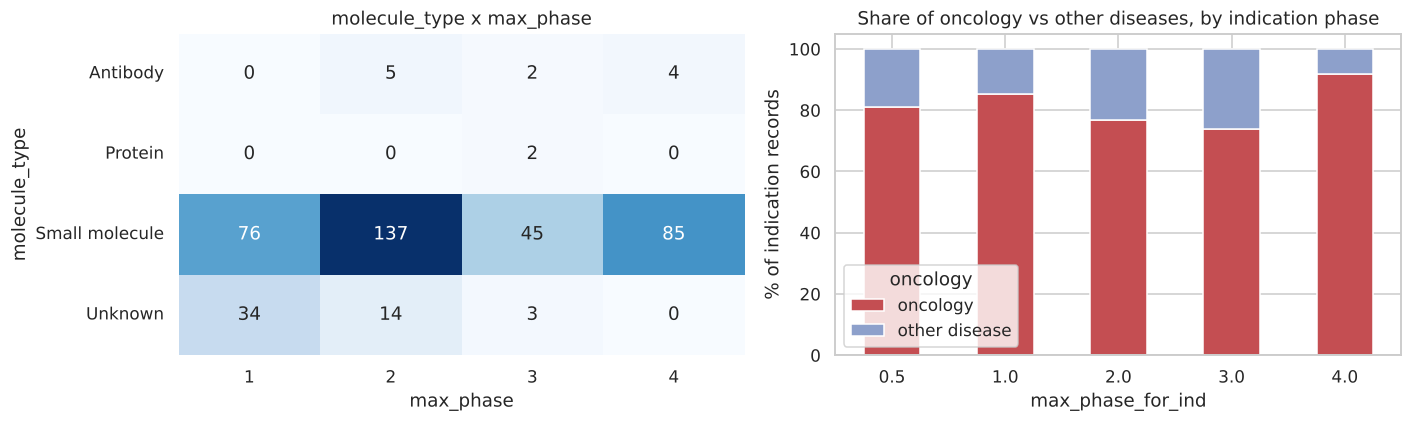


activities: measurement type x raw unit (units with > 100 rows):


units,(empty = p-value),nM,nmol/L,uM
standard_type,,,,
IC50,36,4605,144,813
Kd,25,8798,2,238
Ki,614,275,7,34


In [16]:
def cramers_v(t):
    chi2 = chi2_contingency(t)[0]
    return float(np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))))

ONC = (r"neoplasm|carcinoma|leukemia|lymphoma|melanoma|myeloma|sarcoma|glioma|glioblastoma|astrocytoma|cancer|tumou?r|"
       r"blastoma|adenoma|mesothelioma|macroglobulinemia|hodgkin|myelodysplastic|myeloproliferative|polycythemia|mastocytosis|myelofibrosis")
ind["oncology"] = ind.mesh_heading.fillna("").str.contains(ONC, case=False, regex=True).map({True: "oncology", False: "other disease"})

t1 = pd.crosstab(mol.molecule_type, mol.max_phase.astype(int))
t2 = pd.crosstab(ind.oncology, ind.max_phase_for_ind)
print("molecule_type x max_phase: Cramer's V = %.2f" % cramers_v(t1)); display(t1)
print("oncology x indication phase: Cramer's V = %.2f" % cramers_v(t2)); display(t2)
share = (100 * t2.div(t2.sum(axis=0), axis=1)).round(1); print("oncology share (%) by indication phase:", share.loc["oncology"].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(t1, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0]); axes[0].set_title("molecule_type x max_phase")
(100 * t2.div(t2.sum(axis=0), axis=1)).T.plot.bar(stacked=True, ax=axes[1], color=["#C44E52", "#8DA0CB"], rot=0)
axes[1].set_title("Share of oncology vs other diseases, by indication phase"); axes[1].set_ylabel("% of indication records"); axes[1].set_xlabel("max_phase_for_ind")
plt.tight_layout(); plt.show()

print("\nactivities: measurement type x raw unit (units with > 100 rows):")
t3 = pd.crosstab(act.standard_type, act.units.fillna("(empty = p-value)")); display(t3.loc[:, t3.sum() > 100])

share of small molecules with activity records, by phase: {1: 0.75, 2: 0.8, 3: 0.82, 4: 0.68}
approved small molecules with activity records: 58 of 85


,median phase 1/2/3/4,Spearman rho vs phase,Kruskal-Wallis p
per molecule,,,
activity records,12.0 / 17.5 / 25.0 / 38.5,0.223,0.002
kinases measured,6.0 / 6.0 / 7.0 / 9.0,0.079,0.387
indication records,1.0 / 4.0 / 10.0 / 10.0,0.546,0.000
mechanism targets,1.0 / 1.0 / 1.0 / 2.0,0.111,0.003


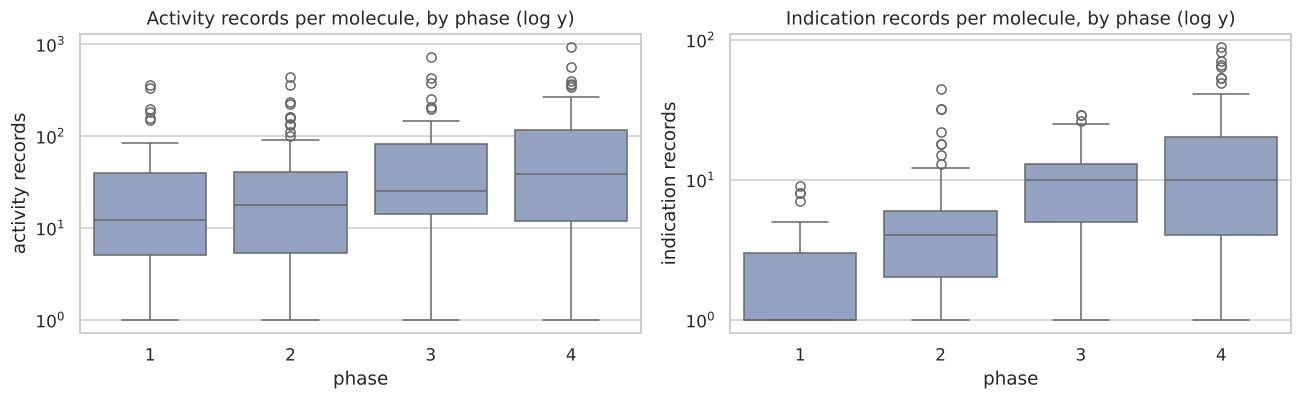

In [17]:
# amount of biological data per small molecule, by development phase
cnt = pd.DataFrame({"activity records": act.groupby("molecule_chembl_id").size(),
                    "kinases measured": act.groupby("molecule_chembl_id").target_chembl_id.nunique(),
                    "indication records": ind.groupby("molecule_chembl_id").size(),
                    "mechanism targets": mech.groupby("molecule_chembl_id").target_chembl_id.nunique()}).reindex(small.molecule_chembl_id)
cnt["phase"] = small.set_index("molecule_chembl_id").max_phase.astype(int)
print("share of small molecules with activity records, by phase:", cnt.assign(has=cnt["activity records"].notna()).groupby("phase").has.mean().round(2).to_dict())
print("approved small molecules with activity records:", int(cnt[cnt.phase == 4]["activity records"].notna().sum()), "of", int((cnt.phase == 4).sum()))
rows = []
for c in ["activity records", "kinases measured", "indication records", "mechanism targets"]:
    g = [cnt[cnt.phase == p][c].dropna() for p in phases]; sub = cnt.dropna(subset=[c])
    rows.append({"per molecule": c, "median phase 1/2/3/4": " / ".join(f"{x.median():.1f}" for x in g),
                 "Spearman rho vs phase": spearmanr(sub.phase, sub[c])[0], "Kruskal-Wallis p": kruskal(*g)[1]})
display(pd.DataFrame(rows).set_index("per molecule").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=cnt.dropna(subset=["activity records"]), x="phase", y="activity records", ax=axes[0], color="#8DA0CB"); axes[0].set_yscale("log"); axes[0].set_title("Activity records per molecule, by phase (log y)")
sns.boxplot(data=cnt.dropna(subset=["indication records"]), x="phase", y="indication records", ax=axes[1], color="#8DA0CB"); axes[1].set_yscale("log"); axes[1].set_title("Indication records per molecule, by phase (log y)")
plt.tight_layout(); plt.show()

**Conclusion 7.4**
- **(a) Type vs phase** (Cramér's V = 0.23, weak to moderate): all 51 *Unknown* molecules are early-phase (34 in phase 1, 14 in phase 2, 3 in phase 3, none approved), while the 4 approved antibodies and the 85 approved small molecules make up phase 4. The *Unknown* type is therefore a pipeline-stage artifact: early compounds without a clean structure record.
- **(b) Oncology vs phase** (Cramér's V = 0.14, weak): oncology dominates every level (74–86% of the records in phases 0.5–3) and reaches **92% among approved indications**, while **26% of the phase-3 indications are non-oncology**. Non-oncology uses are still in clinical trials rather than approved, which is relevant for the repurposing hypotheses.
- **Measurement type vs unit:** most IC50 and Kd values are in nM; two thirds of the Ki values (614 of 935) are reported as p-values.
- **(c) Biological data per molecule:** more advanced molecules have more records. Activity records per molecule increase with phase (median 12 / 17.5 / 25 / 38.5, ρ = 0.22, Kruskal–Wallis p = 0.002) and indication records increase much more strongly (median 1 / 4 / 10 / 10; ρ = 0.55, p < 0.001). The number of kinases measured per molecule does *not* depend clearly on the phase (medians 6 / 6 / 7 / 9, p = 0.39).
- **Coverage:** 75%, 80%, 82% and 68% of the small molecules in phases 1 to 4 have activity records; only **58 of the 85 approved small molecules** have any (counted on raw IDs, where a salt form may carry the data of its free base). The approved drugs are not the best covered group, which matters for the biological interpretation.

**Output of Step 7.** The correlation matrix (`correlation_matrix_molecules.csv`) and the relationship plots above. The main lessons: the descriptors are related but not redundant; the apparent differences between phases are an artifact of the salt forms; potency must be analyzed per measurement type; and the amount of biological information grows with the development phase.

---
# Step 8 — Outlier analysis
Objective: find extreme values with boxplots and the IQR rule, investigate each group of extremes, and decide whether they are **valid** (a real, unusual observation), an **artifact** (caused by a data problem) or **suspicious** (needs review). An outlier is not automatically an error: in drug data many extremes are real molecules.

### 8.1 Boxplots
Boxplots show the median, the quartiles and the points beyond 1.5×IQR (dots). The first figure shows the molecule variables; the second the activity-related variables and two per-molecule counts that we derive (records per molecule), shown on a log scale where the spread is large.

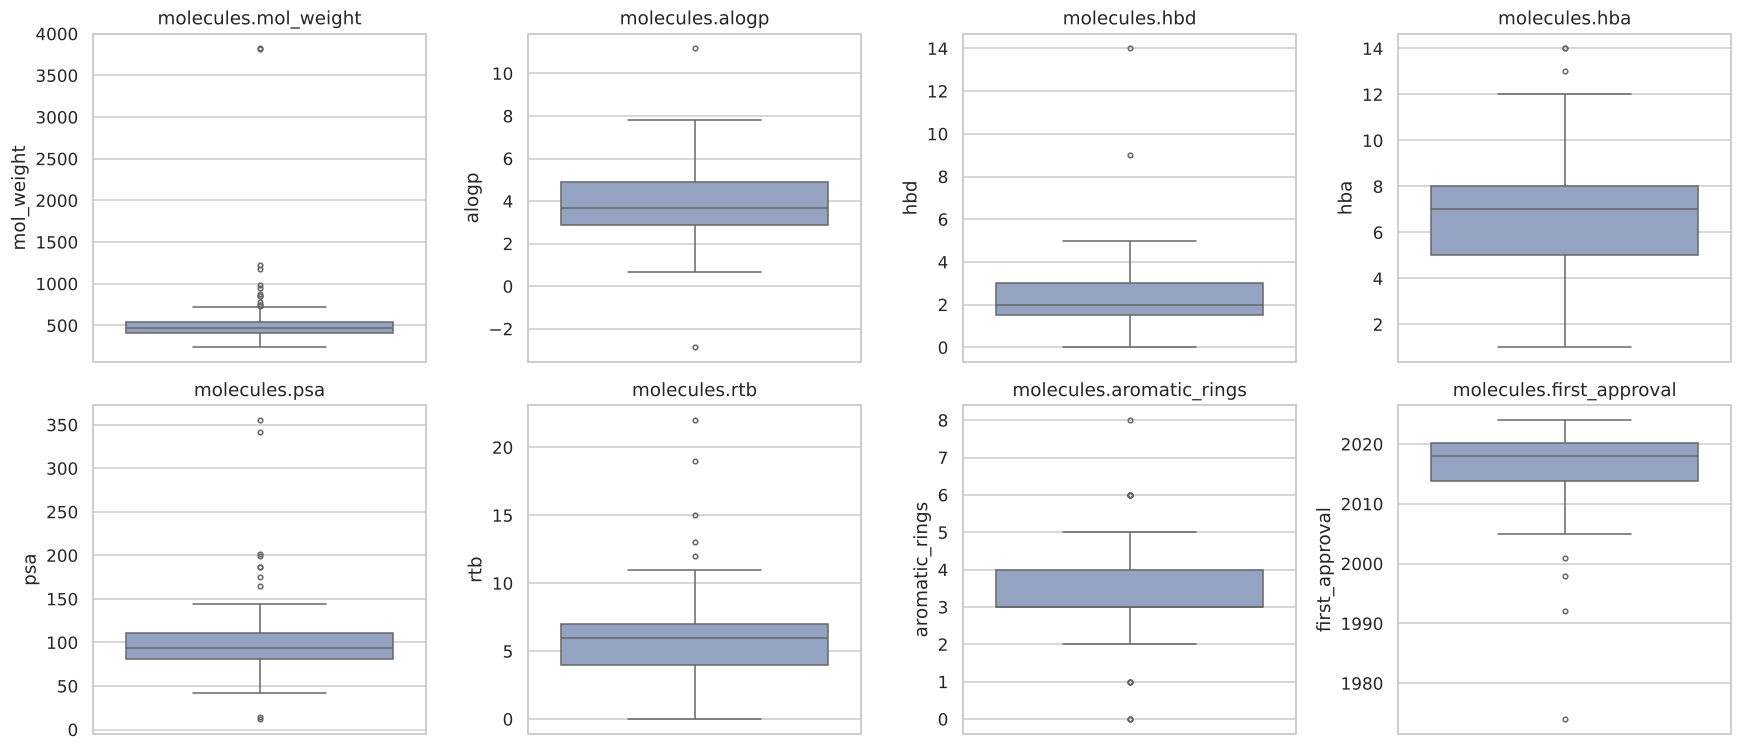

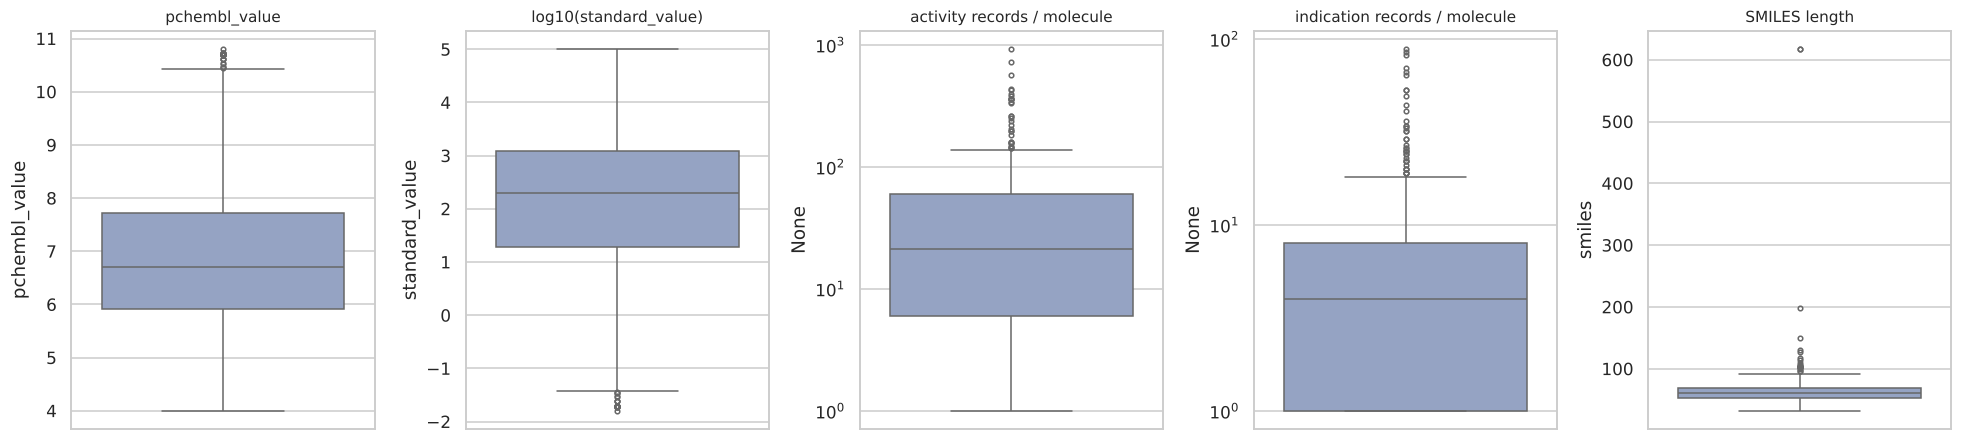

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel()[:7], D):
    sns.boxplot(y=mol[c], ax=ax, color="#8DA0CB", flierprops={"markersize": 3}); ax.set_title(f"molecules.{c}")
sns.boxplot(y=mol.first_approval, ax=axes[1, 3], color="#8DA0CB", flierprops={"markersize": 3}); axes[1, 3].set_title("molecules.first_approval")
plt.tight_layout(); plt.show()

n_act = act.groupby("molecule_chembl_id").size(); n_ind = ind.groupby("molecule_chembl_id").size()
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
for ax, (s, t, lg) in zip(axes, [(act.pchembl_value, "pchembl_value", False), (np.log10(act.standard_value), "log10(standard_value)", False),
                                  (n_act, "activity records / molecule", True), (n_ind, "indication records / molecule", True),
                                  (mol.smiles.str.len().dropna(), "SMILES length", False)]):
    sns.boxplot(y=s, ax=ax, color="#8DA0CB", flierprops={"markersize": 3}); ax.set_title(t, fontsize=10)
    if lg: ax.set_yscale("log")
plt.tight_layout(); plt.show()

**Conclusion 8.1**
- The molecule descriptors show a few isolated points on the high side (`mol_weight`, `psa`, `hbd`, `rtb`, `hba`) and on both sides for `alogp`, `psa` and `aromatic_rings`; `first_approval` has dots only on the old side.
- `pchembl_value` has dots only at the potent end; the log₁₀ concentration is almost the mirror image.
- The per-molecule record counts have many dots even on a log scale: heavy tails, as seen in 6.4. The SMILES length has two clear extremes (the peptides) and a cloud of moderately long values.

### 8.2 The IQR method
A value is a **mild** outlier if it lies beyond Q1 − 1.5×IQR or Q3 + 1.5×IQR, and **extreme** beyond 3×IQR (IQR = Q3 − Q1). The method assumes a roughly symmetric variable, so for the concentration we apply it both to the raw `standard_value` and to its log₁₀ to show the difference.

In [19]:
def iqr_row(ds, name, s):
    s = pd.Series(s).dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    lo, hi, lo3, hi3 = q1 - 1.5 * i, q3 + 1.5 * i, q1 - 3 * i, q3 + 3 * i
    mild, ext = (s < lo) | (s > hi), (s < lo3) | (s > hi3)
    return {"dataset": ds, "variable": name, "n": len(s), "Q1": q1, "Q3": q3, "IQR": i, "lower fence": lo, "upper fence": hi,
            "mild outliers": int(mild.sum()), "of which extreme (3xIQR)": int(ext.sum()), "% mild": round(100 * mild.mean(), 1),
            "low side": int((s < lo).sum()), "high side": int((s > hi).sum())}

rows = [iqr_row("molecules", c, mol[c]) for c in D + ["first_approval"]]
rows += [iqr_row("activities", "pchembl_value", act.pchembl_value),
         iqr_row("activities", "standard_value (raw nM)", act.standard_value),
         iqr_row("activities", "log10(standard_value)", np.log10(act.standard_value)),
         iqr_row("derived", "activity records per molecule", n_act),
         iqr_row("derived", "indication records per molecule", n_ind),
         iqr_row("molecules", "SMILES length", mol.smiles.str.len())]
iqr_table = pd.DataFrame(rows)
iqr_table.round(2)

,dataset,variable,n,Q1,Q3,IQR,lower fence,upper fence,mild outliers,of which extreme (3xIQR),% mild,low side,high side
0,molecules,mol_weight,345,412.42,540.02,127.60,221.02,731.42,13,6,3.8,0,13
1,molecules,alogp,343,2.88,4.88,2.00,-0.13,7.89,2,1,0.6,1,1
2,molecules,hbd,343,1.50,3.00,1.50,-0.75,5.25,2,2,0.6,0,2
3,molecules,hba,343,5.00,8.00,3.00,0.50,12.50,3,0,0.9,0,3
4,molecules,psa,343,80.55,110.66,30.11,35.38,155.84,10,3,2.9,2,8
5,molecules,rtb,343,4.00,7.00,3.00,-0.50,11.50,5,2,1.5,0,5
6,molecules,aromatic_rings,343,3.00,4.00,1.00,1.50,5.50,14,1,4.1,7,7
7,molecules,first_approval,88,2013.75,2020.25,6.50,2004.00,2030.00,4,2,4.5,4,0
8,activities,pchembl_value,15655,5.91,7.72,1.81,3.20,10.43,19,0,0.1,0,19
9,activities,standard_value (raw nM),15655,19.00,1233.00,1214.00,-1802.00,3054.00,1825,1022,11.7,0,1825


**Conclusion 8.2**
- **Molecules:** `mol_weight` has 13 mild outliers (6 extreme; all on the high side, fences 221–731), `psa` 10, `rtb` 5, `hba` 3, `hbd` 2, `alogp` 2, `aromatic_rings` 14 (7 on each side), `first_approval` 4 (all old; fence 2004).
- **Potency:** `pchembl_value` has 19 high outliers (above 10.4, i.e. sub-0.04 nM) and none on the low side.
- **The method misleads on skewed variables:** applied to the raw `standard_value` it flags 1 825 records (11.7%, 1 022 of them extreme), simply because the variable is log-distributed; on the log₁₀ scale it flags the same 19 records as the pChEMBL value. The raw concentration should never be screened with the IQR rule.
- **Record counts:** 30 of the 262 measured molecules have more than 140 activity records (17 beyond 221), 39 of the 359 molecules with indications have more than 18 indication records (17 extreme), and 20 SMILES are longer than 92 characters (7 extreme).

### 8.3 Investigating the extreme values
For each group of outliers we ask *why* it is extreme. For the molecule descriptors we classify each outlier by a rule: **not a small molecule** (peptide, antibody), **artifact** (a salt/solvate whose parent structure falls inside the fences, i.e. the counter-ion creates the outlier; this applies to the molecular weight, the only descriptor ChEMBL computes on the full salt), or **genuine** (an unusual but real molecule).

In [20]:
lfc, unc = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()
m = mol.dropna(subset=["smiles"]).copy()
m["n_frag"] = m.smiles.str.count(r"\.") + 1
m["mw_parent"] = m.smiles.apply(lambda s: Descriptors.MolWt(unc.uncharge(lfc.choose(Chem.MolFromSmiles(s)))))

recs = []
for c in D:
    s = m[c].dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    for _, r in m[(m[c] < lo) | (m[c] > hi)].iterrows():
        if r.molecule_type != "Small molecule": cause = "not a small molecule"
        elif c == "mol_weight" and r.n_frag > 1 and lo <= r.mw_parent <= hi: cause = "artifact (counter-ion)"
        else: cause = "genuine (unusual molecule)"
        recs.append({"variable": c, "name": r["name"], "type": r.molecule_type, "value": round(r[c], 1),
                     "MW of parent": round(r.mw_parent, 1), "fragments": r.n_frag, "max_phase": int(r.max_phase), "cause": cause})
out = pd.DataFrame(recs)
print("Classification of the outliers by descriptor:")
display(out.groupby(["variable", "cause"]).size().unstack(fill_value=0).reindex(D))
print("Molecular weight outliers:")
display(out[out.variable == "mol_weight"].sort_values("value", ascending=False).drop(columns="variable").reset_index(drop=True))
multi = out.groupby("name").variable.agg(n="count", descriptors=lambda s: ", ".join(s)).query("n >= 3").sort_values("n", ascending=False)
print("Molecules that are outliers on 3 or more descriptors:"); display(multi)

Classification of the outliers by descriptor:


cause,artifact (counter-ion),genuine (unusual molecule),not a small molecule
variable,,,
mol_weight,8,3,2
alogp,0,2,0
hbd,0,2,0
hba,0,3,0
psa,0,10,0
rtb,0,5,0
aromatic_rings,0,14,0


Molecular weight outliers:


,name,type,value,MW of parent,fragments,max_phase,cause
0,"BRIMAPITIDE, C-TERMINAL ACID",Protein,3823.5,3823.5,1,3,not a small molecule
1,BRIMAPITIDE,Protein,3822.5,3822.5,1,3,not a small molecule
2,GILTERITINIB FUMARATE,Small molecule,1221.5,552.7,3,4,artifact (counter-ion)
3,COBIMETINIB FUMARATE,Small molecule,1178.7,531.3,3,4,artifact (counter-ion)
4,RIDAFOROLIMUS,Small molecule,990.2,990.2,1,3,genuine (unusual molecule)
5,LAPATINIB DITOSYLATE,Small molecule,943.5,581.1,4,4,artifact (counter-ion)
6,RSM-932A,Small molecule,877.5,717.7,3,1,artifact (counter-ion)
7,SF-1126,Small molecule,852.9,852.9,1,2,genuine (unusual molecule)
8,AV-412,Small molecule,851.4,507.0,3,1,artifact (counter-ion)
9,UPADACITINIB HEMIHYDRATE,Small molecule,778.8,380.4,3,4,artifact (counter-ion)


Molecules that are outliers on 3 or more descriptors:


,n,descriptors
name,,
SF-1126,6,"mol_weight, alogp, hbd, hba, psa, rtb"
RIDAFOROLIMUS,4,"mol_weight, hba, psa, aromatic_rings"
RSM-932A,4,"mol_weight, alogp, psa, aromatic_rings"
SEMAPIMOD,4,"mol_weight, hbd, psa, rtb"


**Conclusion 8.3 (molecules)**
- **Molecular weight (13 outliers):** **2 are not small molecules** (the brimapitide peptides, MW ≈ 3 823), **8 are counter-ion artifacts** (gilteritinib fumarate 1 222 → 553 for the parent, cobimetinib fumarate 1 179 → 531, lapatinib ditosylate 943 → 581, RSM-932A, AV-412, upadacitinib hemihydrate, umbralisib tosylate, fostamatinib disodium) and **3 are genuine**: ridaforolimus (990), SF-1126 (853) and semapimod (745).
- **All the other descriptors are outliers because of genuine molecules.** The same few are extreme on several descriptors at once: SF-1126 (6 descriptors), then semapimod, ridaforolimus and RSM-932A (4 each). SF-1126 and semapimod are large and very polar (PSA 342 and 355), ridaforolimus is a macrocycle (a rapamycin analogue) with no aromatic ring, and RSM-932A is a very lipophilic compound (logP 11.2): chemically unusual, but real molecules.
- **Decision (molecules):** exclude the 2 peptides (not small molecules); the 8 artifacts disappear when the molecular weight is recomputed on the parent structure; keep the 3 genuine heavy molecules but **flag them** and compare the clustering with and without them, since they will sit far from the others.

In [21]:
# --- activities: potency extremes
hi = act[act.pchembl_value > 10.43].assign(molecule=lambda d: d.molecule_chembl_id.map(nm))
print("pChEMBL > 10.43:", len(hi), "records")
display(hi.groupby(["molecule", "target_pref_name", "standard_type"]).size().sort_values(ascending=False).head(6).rename("records").reset_index())
print("highest potency:", act.loc[act.pchembl_value.idxmax(), ["standard_value", "pchembl_value", "standard_type"]].to_dict(), "->", nm[act.loc[act.pchembl_value.idxmax(), "molecule_chembl_id"]])
print("lowest potency: pchembl == 4.0 in", int((act.pchembl_value == 4.0).sum()), "records | standard_value == 100000 nM in", int((act.standard_value == 100000).sum()), "record | >= 50000 nM in", int((act.standard_value >= 50000).sum()))

# --- activity records per molecule
c = act.groupby("molecule_chembl_id").agg(records=("pchembl_value", "size"), kinases=("target_chembl_id", "nunique"),
                                          kd_share=("standard_type", lambda s: (s == "Kd").mean())).assign(name=lambda d: d.index.map(nm)).sort_values("records", ascending=False)
heavy = c[c.records > 140.38]
print("\nmolecules with > 140 activity records:", len(heavy), "of", len(c), "| share of all records: %.1f%%" % (100 * heavy.records.sum() / len(act)))
print("median kinases measured: %.1f (these) vs %.1f (others) | mean share of Kd: %.0f%%" % (heavy.kinases.median(), c[c.records <= 140.38].kinases.median(), 100 * heavy.kd_share.mean()))
display(c.head(8)[["name", "records", "kinases", "kd_share"]].round(2).reset_index(drop=True))

# --- indications per molecule
ci = n_ind.sort_values(ascending=False).head(6)
print("most indication records:", {nm[i]: int(v) for i, v in ci.items()})
print("molecules with > 18.5 indication records:", int((n_ind > 18.5).sum()), "| by phase:", mol.set_index("molecule_chembl_id").loc[n_ind[n_ind > 18.5].index].max_phase.astype(int).value_counts().sort_index().to_dict())

pChEMBL > 10.43: 19 records


,molecule,target_pref_name,standard_type,records
0,OMIPALISIB,"Phosphatidylinositol 4,5-bisphosphate 3-kinase...",Ki,4
1,DEUCRAVACITINIB,Non-receptor tyrosine-protein kinase TYK2,Ki,3
2,OMIPALISIB,"Phosphatidylinositol 4,5-bisphosphate 3-kinase...",Ki,3
3,BOSUTINIB,Tyrosine-protein kinase ABL1,Kd,2
4,INAVOLISIB,"Phosphatidylinositol 4,5-bisphosphate 3-kinase...",Ki,2
5,CRENOLANIB,Receptor-type tyrosine-protein kinase FLT3,Kd,1


highest potency: {'standard_value': 0.016, 'pchembl_value': 10.8, 'standard_type': 'Kd'} -> CRENOLANIB
lowest potency: pchembl == 4.0 in 3 records | standard_value == 100000 nM in 1 record | >= 50000 nM in 26

molecules with > 140 activity records: 30 of 262 | share of all records: 58.6%
median kinases measured: 107.5 (these) vs 5.0 (others) | mean share of Kd: 63%


,name,records,kinases,kd_share
0,SUNITINIB,918,234,0.90
1,LESTAURTINIB,722,298,0.97
2,MIDOSTAURIN,567,188,0.97
3,SU-014813,433,213,1.00
4,DOVITINIB,425,179,0.82
5,FEDRATINIB,391,234,0.77
6,ALVOCIDIB,380,136,0.71
7,IBRUTINIB,362,30,0.10


most indication records: {'DASATINIB ANHYDROUS': 88, 'TRASTUZUMAB': 85, 'IMATINIB MESYLATE': 82, 'SORAFENIB TOSYLATE': 70, 'SUNITINIB': 66, 'SUNITINIB MALATE': 64}
molecules with > 18.5 indication records: 39 | by phase: {2: 4, 3: 9, 4: 26}


**Conclusion 8.3 (activities and indications)**
- **Potency outliers are valid.** The 19 records above pChEMBL 10.4 belong to very potent inhibitors on their primary kinase, mostly measured as Ki or Kd: omipalisib on PI3K isoforms, deucravacitinib on TYK2, inavolisib on PI3Kα, bosutinib on ABL1 and crenolanib on FLT3 (the maximum, 10.8, i.e. 0.016 nM). There are no low-side outliers: the weakest records stay at pChEMBL 4.0 (3 records, only 1 at 100 000 nM), so the table contains almost no weak or inactive measurements.
- **Record-count outliers are real but biased.** 30 molecules (11% of those measured) hold **59% of all activity records**. They are measured on a median of 108 kinases (against 5 for the others) and 63% of their records are Kd values: they come from broad kinome-profiling panels (sunitinib 918 records on 234 kinases, lestaurtinib 722, midostaurin 567). The values are correct, but these molecules would dominate any statistic computed per record.
- **Indications:** 39 molecules have more than 18 indication records (26 of them approved): dasatinib (88), trastuzumab (85, an antibody), imatinib (82), sorafenib (70), sunitinib (66). Valid, and expected for the most widely used drugs.
- **Decision (activities):** keep all records, drop the exact duplicates, aggregate per (molecule, kinase, type) and avoid per-record statistics; never apply the IQR rule to the raw concentration.

In [22]:
# --- approval years
fa = mol.dropna(subset=["first_approval"]).sort_values("first_approval").head(6)[["name", "first_approval", "molecule_type", "molecule_chembl_id"]]
fa["first_approval"] = fa.first_approval.astype(int); display(fa.reset_index(drop=True))
for name_ in ["PERHEXILINE MALEATE", "MASOPROCOL"]:
    cid = mol.loc[mol.name == name_, "molecule_chembl_id"].iloc[0]
    print(f"\n{name_} ({cid}): mechanism ->", mech[mech.molecule_chembl_id == cid].mechanism_of_action.tolist(),
          "| activity records:", int((act.molecule_chembl_id == cid).sum()), "| indications:", ind[ind.molecule_chembl_id == cid].efo_term.tolist()[:3])

# --- SMILES length
sl = mol.assign(L=mol.smiles.str.len(), n_frag=mol.smiles.str.count(r"\.") + 1).dropna(subset=["L"])
print("\nSMILES longer than 92 characters:", int((sl.L > 92).sum()), "| of which salts/solvates:", int(((sl.L > 92) & (sl.n_frag > 1)).sum()), "| not small molecules:", int(((sl.L > 92) & (sl.molecule_type != "Small molecule")).sum()))
display(sl.sort_values("L", ascending=False).head(8)[["name", "molecule_type", "L", "n_frag"]].reset_index(drop=True))

,name,first_approval,molecule_type,molecule_chembl_id
0,PERHEXILINE MALEATE,1974,Small molecule,CHEMBL1334033
1,MASOPROCOL,1992,Small molecule,CHEMBL313972
2,TRASTUZUMAB,1998,Antibody,CHEMBL1201585
3,IMATINIB MESYLATE,2001,Small molecule,CHEMBL1642
4,SORAFENIB TOSYLATE,2005,Small molecule,CHEMBL1200485
5,DASATINIB ANHYDROUS,2006,Small molecule,CHEMBL1421



PERHEXILINE MALEATE (CHEMBL1334033): mechanism -> ['Serine/threonine-protein kinase mTOR inhibitor'] | activity records: 0 | indications: []

MASOPROCOL (CHEMBL313972): mechanism -> ['Receptor protein-tyrosine kinase erbB-2 inhibitor'] | activity records: 0 | indications: ['neoplasm', 'prostate cancer']

SMILES longer than 92 characters: 20 | of which salts/solvates: 13 | not small molecules: 2


,name,molecule_type,L,n_frag
0,BRIMAPITIDE,Protein,617.0,1.0
1,"BRIMAPITIDE, C-TERMINAL ACID",Protein,617.0,1.0
2,RIDAFOROLIMUS,Small molecule,199.0,1.0
3,GILTERITINIB FUMARATE,Small molecule,149.0,3.0
4,COBIMETINIB FUMARATE,Small molecule,131.0,3.0
5,SF-1126,Small molecule,127.0,1.0
6,UPADACITINIB HEMIHYDRATE,Small molecule,117.0,3.0
7,LAPATINIB DITOSYLATE,Small molecule,114.0,4.0


**Conclusion 8.3 (approval years and SMILES)**
- **Approval years:** the 4 old values are perhexiline maleate (1974), masoprocol (1992), trastuzumab (1998) and imatinib mesylate (2001). The years themselves are plausible, but **two of these molecules are suspicious members of the kinase-inhibitor family**: perhexiline maleate has only a mechanism record (mTOR inhibitor), no activity records and no indication; masoprocol has a mechanism record (erbB-2 inhibitor) and two cancer indications but no activity records. Trastuzumab is an antibody, not a small molecule. These records should be reviewed, because nothing in the data confirms that they inhibit a kinase.
- **SMILES length:** of the 20 SMILES longer than 92 characters, 2 are the peptides and **13 are salt forms** (the counter-ion adds characters); the others include macrocycles such as ridaforolimus. The result agrees with the molecular-weight outliers.

### 8.4 Output: outlier report
One row per variable with its fences, the number of outliers, the cause found in 8.3, the assessment (valid, artifact or suspicious) and the decision. The counts come from the previous cells. Saved as `data/reports/outlier_report.csv`.

In [23]:
def cnt_(variable, cause): return int(((out.variable == variable) & (out.cause == cause)).sum())
T = iqr_table.set_index("variable")
def row(var, key, cause, assessment, decision, ds=None):
    r = T.loc[key]
    return {"dataset": r.dataset, "variable": var, "n": int(r.n), "lower fence": round(r["lower fence"], 2), "upper fence": round(r["upper fence"], 2),
            "mild outliers": int(r["mild outliers"]), "extreme (3xIQR)": int(r["of which extreme (3xIQR)"]),
            "cause": cause, "assessment": assessment, "decision": decision}

mw = out[out.variable == "mol_weight"]
rows = [
 row("mol_weight", "mol_weight", f"{cnt_('mol_weight', 'not a small molecule')} peptides; {cnt_('mol_weight', 'artifact (counter-ion)')} counter-ion artifacts; {cnt_('mol_weight', 'genuine (unusual molecule)')} genuine heavy molecules (ridaforolimus, SF-1126, semapimod)",
     "Mixed: 2 invalid for the project, 8 artifacts, 3 valid", "Exclude the peptides; recompute MW on the parent structure; keep and flag the 3 genuine ones"),
 row("alogp", "alogp", "RSM-932A (very lipophilic) and SF-1126 (very hydrophilic)", "Valid (unusual molecules)", "Keep, flag"),
 row("hbd", "hbd", "Semapimod (14 donors), SF-1126 (9)", "Valid (unusual molecules)", "Keep, flag"),
 row("hba", "hba", "SF-1126, ridaforolimus, ARQ-736", "Valid (unusual molecules)", "Keep, flag"),
 row("psa", "psa", "Very polar large molecules (semapimod, SF-1126) and 2 very apolar ones (RSM-932A, perhexiline)", "Valid (unusual molecules)", "Keep, flag"),
 row("rtb", "rtb", "SF-1126 (22), semapimod (19), baraserib and others", "Valid (flexible large molecules)", "Keep, flag"),
 row("aromatic_rings", "aromatic_rings", "7 molecules with many rings (up to 8), 7 with almost none (macrocycles, non-aromatic)", "Valid (unusual molecules)", "Keep"),
 row("first_approval", "first_approval", "Old approvals: perhexiline (1974), masoprocol (1992), trastuzumab (1998), imatinib (2001); the first two have no activity data", "Valid years; perhexiline and masoprocol are suspicious members of the kinase family", "Keep the year; review the two molecules' kinase annotation"),
 row("pchembl_value", "pchembl_value", "Very potent inhibitor-kinase pairs (omipalisib, deucravacitinib, inavolisib, bosutinib, crenolanib), mostly Ki / Kd", "Valid", "Keep"),
 row("standard_value (raw nM)", "standard_value (raw nM)", "Log-distributed variable: the IQR rule on a linear scale flags 11.7% of the rows", "Method artifact", "Do not use the IQR rule on the raw concentration; use the log scale / pChEMBL"),
 row("activity records per molecule", "activity records per molecule", "30 molecules from kinome-wide profiling panels hold 59% of the records (sunitinib 918)", "Valid but a source of bias", "Keep; aggregate per (molecule, kinase, type); avoid per-record statistics"),
 row("indication records per molecule", "indication records per molecule", "Widely used drugs (dasatinib 88, trastuzumab 85, imatinib 82)", "Valid", "Keep; count distinct diseases rather than records"),
 row("SMILES length", "SMILES length", "2 peptides, salt forms and macrocycles", "Consistent with the MW outliers", "Handled by the molecule selection and desalting"),
]
outlier_report = pd.DataFrame(rows)
outlier_report.to_csv(REPORT_DIR / "outlier_report.csv", index=False, encoding="utf-8-sig")
print("saved:", REPORT_DIR / "outlier_report.csv")
outlier_report

saved: data/reports/outlier_report.csv


,dataset,variable,n,lower fence,upper fence,mild outliers,extreme (3xIQR),cause,assessment,decision
0,molecules,mol_weight,345,221.02,731.42,13,6,2 peptides; 8 counter-ion artifacts; 3 genuine...,"Mixed: 2 invalid for the project, 8 artifacts,...",Exclude the peptides; recompute MW on the pare...
1,molecules,alogp,343,-0.13,7.89,2,1,RSM-932A (very lipophilic) and SF-1126 (very h...,Valid (unusual molecules),"Keep, flag"
2,molecules,hbd,343,-0.75,5.25,2,2,"Semapimod (14 donors), SF-1126 (9)",Valid (unusual molecules),"Keep, flag"
3,molecules,hba,343,0.50,12.50,3,0,"SF-1126, ridaforolimus, ARQ-736",Valid (unusual molecules),"Keep, flag"
4,molecules,psa,343,35.38,155.84,10,3,"Very polar large molecules (semapimod, SF-1126...",Valid (unusual molecules),"Keep, flag"
5,molecules,rtb,343,-0.50,11.50,5,2,"SF-1126 (22), semapimod (19), baraserib and ot...",Valid (flexible large molecules),"Keep, flag"
6,molecules,aromatic_rings,343,1.50,5.50,14,1,"7 molecules with many rings (up to 8), 7 with ...",Valid (unusual molecules),Keep
7,molecules,first_approval,88,2004.00,2030.00,4,2,"Old approvals: perhexiline (1974), masoprocol ...",Valid years; perhexiline and masoprocol are su...,Keep the year; review the two molecules' kinas...
8,activities,pchembl_value,15655,3.20,10.43,19,0,Very potent inhibitor-kinase pairs (omipalisib...,Valid,Keep
9,activities,standard_value (raw nM),15655,-1802.00,3054.00,1825,1022,Log-distributed variable: the IQR rule on a li...,Method artifact,Do not use the IQR rule on the raw concentrati...


**Conclusion — Step 8**
- The **outliers are mostly valid observations**, not errors: the potent inhibitor–kinase pairs, the heavy and polar macrocycles and the widely used drugs are real.
- **Three groups need action:** (1) the 2 peptides and the 8 salt forms that make up 10 of the 13 molecular-weight outliers (not small molecules, or an artifact of the counter-ion); (2) the raw concentration, for which the IQR rule is inappropriate; (3) perhexiline maleate and masoprocol, two old approved molecules whose kinase-inhibitor status is not supported by any activity record.
- **One structural bias:** a few molecules from kinome-wide panels hold most of the potency records.
- The report is saved as `outlier_report.csv`.

---
## Summary of Phase 3 (Steps 6–8)
| # | Finding | Consequence for the next tasks |
|---|---|---|
| 1 | Molecular weight, `hbd` and `psa` are right-skewed; `alogp`, `aromatic_rings` and `hba` are near symmetric | Standardize; test a robust scaler or a log transform for the skewed descriptors |
| 2 | Concentrations span six orders of magnitude; `pchembl_value` is well behaved | Use `pchembl_value` (never the raw concentration) |
| 3 | Labels (`efo_term`, `mesh_heading`, `mechanism_of_action`) have long tails: 39–42% of the values appear once | Group diseases and mechanisms into broad classes |
| 4 | A few molecules and kinases carry most of the records (sunitinib 918, FLT3 726; 30 molecules = 59% of the activities) | Aggregate per (molecule, kinase, type); avoid per-record statistics |
| 5 | The descriptors are related but no pair reaches 0.70; `pchembl_value` and log(concentration) are identical information | Keep all 7 descriptors; keep only one potency column |
| 6 | The raw molecular weight is inflated by counter-ions: salts weigh 584 vs 455 (median) and create a false difference between phases | Recompute on the parent structure before any comparison |
| 7 | IC50, Ki and Kd are on different levels (7.57 / 6.70 / 6.25) | Analyze potency per measurement type |
| 8 | Approved drugs are not the best covered (58 of 85 have activity data); non-oncology uses are mostly investigational (26% of phase-3 indications, 8% of approved ones) | Expect few repurposing leads among approved drugs and report the coverage |
| 9 | Outliers are mostly genuine; 10 of 13 molecular-weight outliers are peptides or salt artifacts; 2 old approved molecules lack kinase evidence | Exclude peptides, flag the 3 genuine heavy molecules, review perhexiline and masoprocol |

Saved in `data/reports/`: `univariate_numerical_statistics.csv`, `correlation_matrix_molecules.csv`, `outlier_report.csv`.